# DeiT from Scratch: Teaching a Vision Transformer with a CNN Teacher

> **Chapter 4 project (section 4.1):** Build a small Data-efficient image Transformer (DeiT) in PyTorch, train a ResNet-18 teacher on CIFAR-10, and measure what the extra **distillation token** adds to a ViT that learns from only 45,000 images.

## Why this notebook matters

A Vision Transformer starts with almost no assumptions about images. A convolutional network assumes that nearby pixels belong together and that the same pattern can appear anywhere. Those assumptions are why a CNN learns well from a small dataset, and why a plain ViT usually needs far more data to catch up.

DeiT keeps the ViT unchanged and adds one learned token. The **class token** learns from the dataset labels, as in chapter 3. The new **distillation token** learns from the predictions of a trained CNN teacher. The teacher's habits reach the student through that second token, and the student keeps its transformer design.

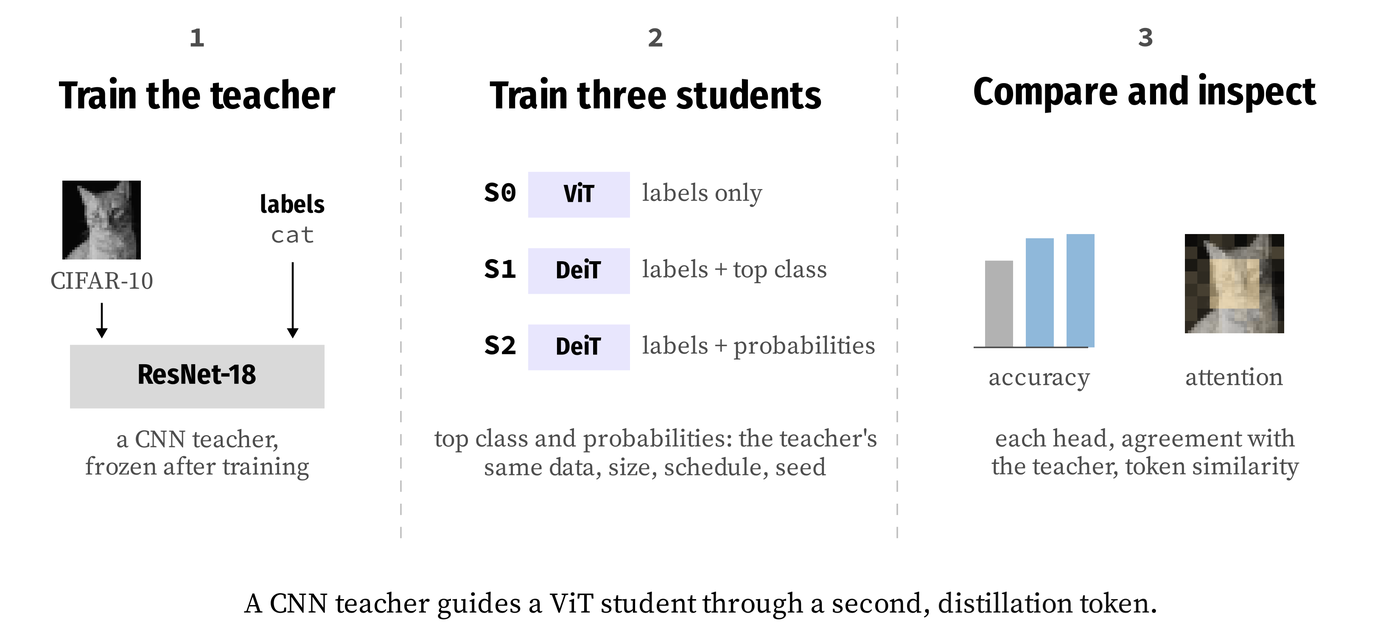

## What you will learn

By the end of this notebook you will be able to:

- build every part of a DeiT student yourself: patch embedding, attention, transformer blocks, class and distillation tokens, and two heads;
- train a CNN teacher and use it to supervise a transformer;
- write **hard** and **soft** distillation losses and explain how they differ;
- show the effect of the distillation token with three controlled runs;
- look inside the trained student: how similar the two tokens become, where they attend, and how often the student agrees with its teacher.

## The four models

| ID | Model | Learns from | The question it answers |
| --- | --- | --- | --- |
| **T** | ResNet-18 (CNN teacher) | labels | How good is the teacher we distill from? |
| **S0** | ViT student, class token only | labels | What does a plain ViT reach on 45,000 images? |
| **S1** | DeiT student, **hard** distillation | labels + teacher's top class | Does the distillation token help? |
| **S2** | DeiT student, **soft** distillation | labels + teacher's probabilities | Is the full probability list better than the top class? |

S0, S1, and S2 have the same width, depth, data, augmentation, schedule, and seed. The only thing that changes is the distillation token and its loss.

## Results at a glance

The saved outputs come from one full run on a T4 GPU (on Modal, 4 CPU cores). Your numbers will differ by a point or so.

| Model | Params | GMACs per image | Test top-1 | Agrees with teacher |
| --- | ---: | ---: | ---: | ---: |
| T ResNet-18 teacher | 11.17M | 0.555 | 91.5% | |
| S0 ViT, labels only | 2.69M | 0.183 | 78.1% | 78.3% |
| S1 DeiT, hard distillation | 2.70M | 0.186 | 80.1% | 80.4% |
| **S2 DeiT, soft distillation** | **2.70M** | **0.186** | **80.7%** | **81.6%** |

- **The distillation token helps.** At the same size and test-time cost, S1 gains 2.0 points and S2 gains 2.6 points over S0.
- **Even the class head improves** (78.1% in S0, 79.8% in S1, 80.7% in S2), although it never sees the teacher. Both heads share the encoder.
- **Soft and hard distillation are close.** Here soft was 0.6 points ahead; the DeiT paper found hard distillation better on ImageNet. With one seed, treat this gap as noise.
- **The student is still far from its teacher** (80.7% against 91.5%) with a quarter of the weights and a third of the work, but it copies more of the teacher's decisions than S0 does (81.6% agreement against 78.3%).

## Roadmap

| Section | What you do | What you get |
| --- | --- | --- |
| 1-3 | Set up the device, settings, and data | CIFAR-10 split into train, validation, and test |
| 4 | Turn an image into tokens | 64 patch tokens plus the special tokens |
| 5-6 | Build attention, the block, and the student | A DeiT student that returns two answers |
| 7 | Build and train the teacher | A ResNet-18 at about 92% accuracy |
| 8 | Write the distillation losses | Hard and soft distillation, with a worked toy example |
| 9-10 | Train three students | S0, S1, and S2, with learning curves |
| 11 | Compare on the test set | Accuracy of each head and agreement with the teacher |
| 12-14 | Look inside | Token similarity, attention maps, and what the teacher changes |
| 15 | Wrap up | Conclusions, limits, and experiments to try |

## Compute budget

| Hardware | Settings | Time |
| --- | --- | --- |
| T4 GPU (Modal, 4 CPU cores) | defaults | **measured:** about 24 minutes of training (teacher 4, S0 5, S1 and S2 7.5 each), plus the one-time CIFAR-10 download (170 MB) |
| T4 GPU (free Colab) | defaults | estimate: 25-40 minutes; with only 2 CPU cores, preparing the augmented images can set the pace |
| CPU only | `TRAIN_SUBSET = 2000`, `EPOCHS = 2`, `TEACHER_EPOCHS = 2` | a few minutes, for following the workflow only |

> **TIP** Every finished model is saved to `./checkpoints`. If Colab disconnects, reconnect and choose **Runtime > Run all**. Finished models are loaded instead of retrained.

## Before you start

You should know the ViT from chapter 3 (patches, class token, positional embeddings) and have read sections 4.1.1 to 4.1.5 on hard and soft distillation. In Colab, choose **Runtime > Change runtime type > T4 GPU** before running anything.

## 1. Imports and device

The notebook needs only PyTorch, torchvision, NumPy, and matplotlib.

| Import | Role |
| --- | --- |
| `torch`, `torch.nn`, `torch.nn.functional` | Tensors, layers, and loss functions |
| `DataLoader`, `Subset` | Mini-batches and the train/validation split |
| `FlopCounterMode` | Counts multiply-accumulate operations to estimate compute |
| `datasets`, `transforms` | CIFAR-10 and its augmentations |
| `matplotlib` | Every plot in this notebook |

In [1]:
#@title Imports
import os, time, math, json
from contextlib import nullcontext
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torch.utils.flop_counter import FlopCounterMode
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
#@title Device
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

cuda


## 2. Hyperparameters

All settings live in one cell, so you can see what stays fixed and change one thing at a time.

| Constant | Value | Meaning |
| --- | ---: | --- |
| `IMG_SIZE`, `PATCH_SIZE` | 32, 4 | A 32 x 32 image cut into 4 x 4 patches gives an 8 x 8 grid of **64 patches** |
| `EMBED_DIM` | 192 | Numbers in each token, as in DeiT-Tiny |
| `HEADS` | 3 | Attention heads, 64 features each, as in DeiT-Tiny |
| `DEPTH` | 6 | Transformer blocks (DeiT-Tiny has 12; 6 keeps training short) |
| `MLP_RATIO` | 4 | The feed-forward layer is 4 times wider than a token |
| `BATCH_SIZE` | 128 | Images per optimizer step |
| `TEACHER_EPOCHS`, `TEACHER_LR` | 15, 0.1 | Teacher schedule: SGD with a one-cycle learning rate |
| `EPOCHS`, `LR`, `WEIGHT_DECAY` | 30, 1e-3, 0.05 | Student schedule: AdamW, linear warmup, then cosine decay |
| `WARMUP_EPOCHS` | 3 | Transformers train more stably if the learning rate starts small |
| `LABEL_SMOOTHING` | 0.1 | Softens the dataset labels for the class head, as DeiT does |
| `ALPHA` | 0.5 | Weight of the distillation loss; the class loss gets `1 - ALPHA` |
| `TEMPERATURE` | 3.0 | Softens the teacher's probabilities in soft distillation (S2 only) |
| `TRAIN_SUBSET` | `None` | Set to a number such as 2000 for a quick CPU run |
| `CKPT_DIR` | `'./checkpoints'` | Where finished models are saved and reloaded |

**In pictures:** what the next cell does.

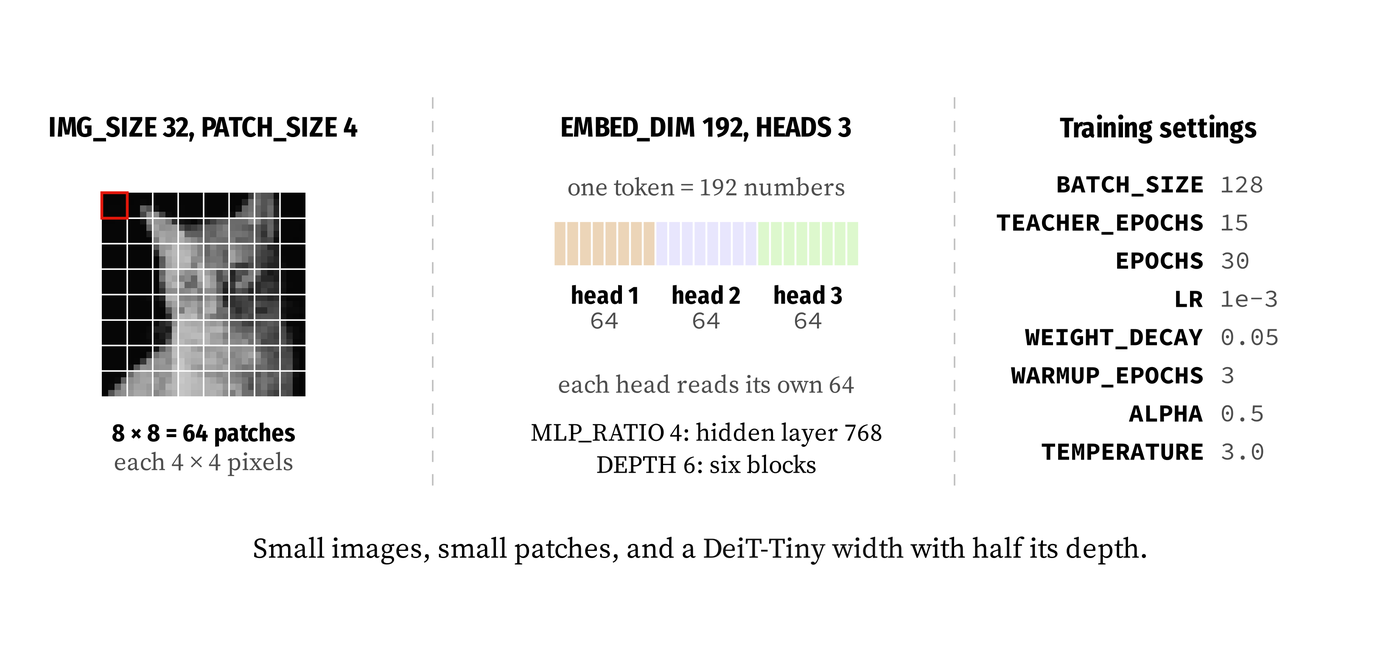

In [3]:
#@title Variables
DATA_DIR = './data'
CKPT_DIR = './checkpoints'
SEED = 42
IMG_SIZE = 32
PATCH_SIZE = 4
CHANNELS = 3
CLASSES = 10
EMBED_DIM = 192
HEADS = 3
DEPTH = 6
MLP_RATIO = 4
BATCH_SIZE = 128
TEACHER_EPOCHS = 15
TEACHER_LR = 0.1
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 3
LABEL_SMOOTHING = 0.1
ALPHA = 0.5
TEMPERATURE = 3.0
TRAIN_SUBSET = None
NUM_WORKERS = min(4, os.cpu_count() or 1)
os.makedirs(CKPT_DIR, exist_ok=True)

## 3. Data: CIFAR-10 with train, validation, and test splits

CIFAR-10 has 60,000 color images of 32 x 32 pixels in ten classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck. It is small enough to train on in minutes, and hard enough that a plain ViT clearly struggles.

```text
CIFAR-10 training set (50,000 images)
 |-- train        45,000   -> learn the weights
 |-- validation    5,000   -> pick the best epoch of each run
CIFAR-10 test set (10,000) -> report final numbers, touched once at the end
```

We never pick anything using the test set. Choosing the best epoch on validation data keeps the test numbers honest.

The teacher and the students see slightly different augmentation:

| Pipeline | Used by | Steps |
| --- | --- | --- |
| `teacher_tfm` | ResNet-18 teacher | random crop with 4 pixels of padding, horizontal flip |
| `student_tfm` | all three students | the same two steps, plus **TrivialAugment** |
| `eval_tfm` | validation and test | no augmentation |

Transformers lack the CNN's built-in assumptions, so they overfit small datasets quickly. The stronger augmentation slows that down. The DeiT paper relies on heavy augmentation for the same reason.

**In pictures:** what the next cell does.

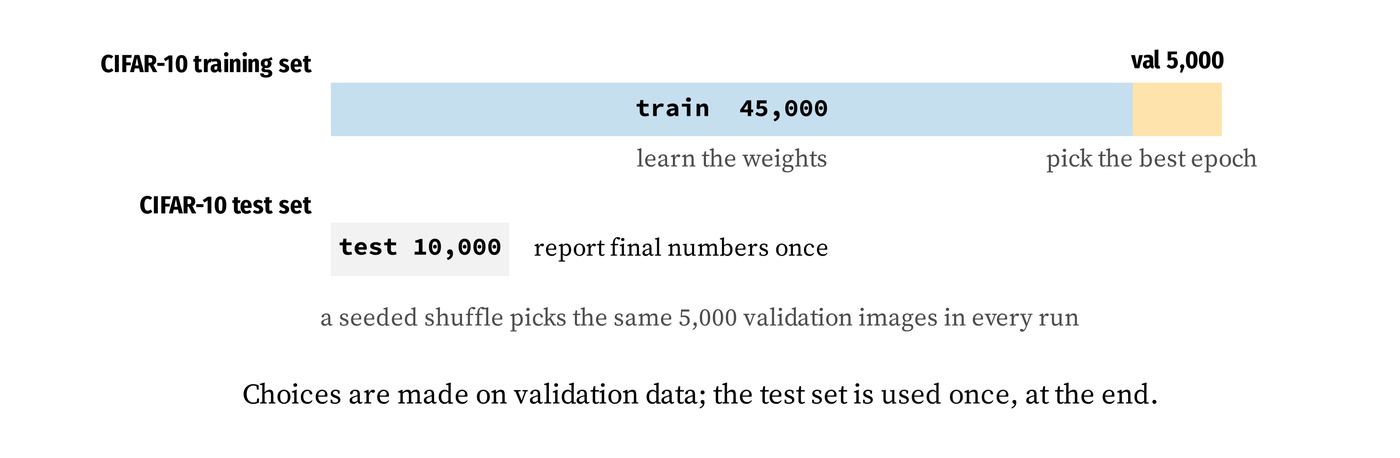
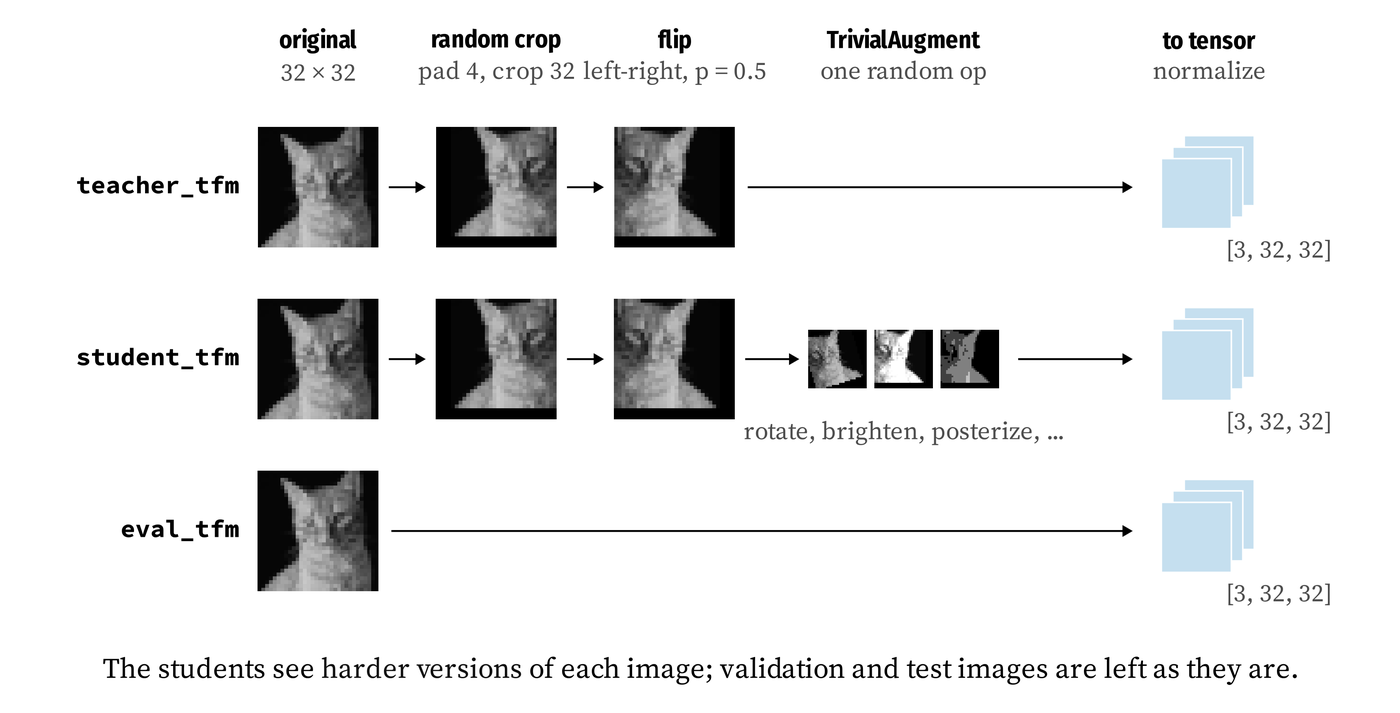

In [4]:
#@title Data
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
normalize = transforms.Normalize(MEAN, STD)
teacher_tfm = transforms.Compose([
    transforms.RandomCrop(IMG_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize])
student_tfm = transforms.Compose([
    transforms.RandomCrop(IMG_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    # Apply one randomly chosen transform at a random strength, such as a rotation,
    # color change, or sharpening.
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(), normalize])
eval_tfm = transforms.Compose([transforms.ToTensor(), normalize])

teacher_train_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=teacher_tfm)
student_train_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=student_tfm)
val_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=eval_tfm)
test_set = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_tfm)
class_names = test_set.classes

order = torch.randperm(50_000, generator=torch.Generator().manual_seed(SEED)).tolist()
# Use the seeded order for the same 45,000 training and 5,000 validation images in each
# full run.
val_idx, train_idx = order[:5_000], order[5_000:]
if TRAIN_SUBSET:
    train_idx, val_idx = train_idx[:TRAIN_SUBSET], val_idx[:TRAIN_SUBSET // 4]

def make_loader(dataset, indices=None, train=False):
    data = Subset(dataset, indices) if indices is not None else dataset
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0,
                      pin_memory=(device == 'cuda'))

teacher_train_dl = make_loader(teacher_train_set, train_idx, train=True)
student_train_dl = make_loader(student_train_set, train_idx, train=True)
val_dl = make_loader(val_set, val_idx)
test_dl = make_loader(test_set)
print(f'train {len(train_idx):,} | validation {len(val_idx):,} | test {len(test_set):,}')

def denorm(x):
    '''Undo the normalization so an image tensor can be shown with matplotlib.'''
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

train 45,000 | validation 5,000 | test 10,000


Let's look at one validation image from each class. Thirty-two pixels is not much: a cat is a few hundred colored squares.

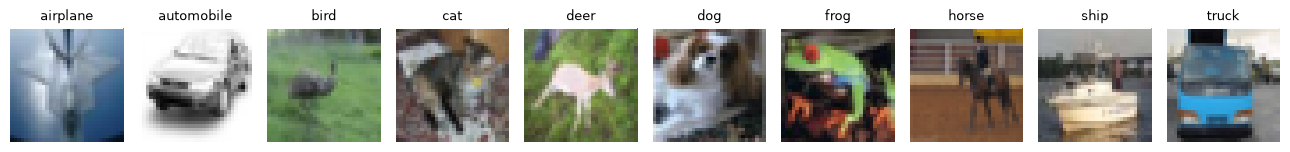

In [5]:
#@title One image per class
targets = np.array(val_set.targets)
fig, axes = plt.subplots(1, 10, figsize=(13, 1.9))
for c, ax in enumerate(axes):
    i = next(i for i in val_idx if targets[i] == c)
    ax.imshow(denorm(val_set[i][0])); ax.set_title(class_names[c], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. From an image to tokens

A transformer reads a sequence of vectors, so the image must become one. The student cuts the 32 x 32 image into an 8 x 8 grid of 4 x 4 patches and turns each patch into a vector of 192 numbers. Then it puts two learned tokens in front of the 64 patch tokens:

| Position | Token | Trained by |
| --- | --- | --- |
| 0 | **CLS**, the class token | the dataset label, through the class head |
| 1 | **DIST**, the distillation token | the teacher's prediction, through the distillation head |
| 2 to 65 | 64 patch tokens | both, indirectly, through attention |

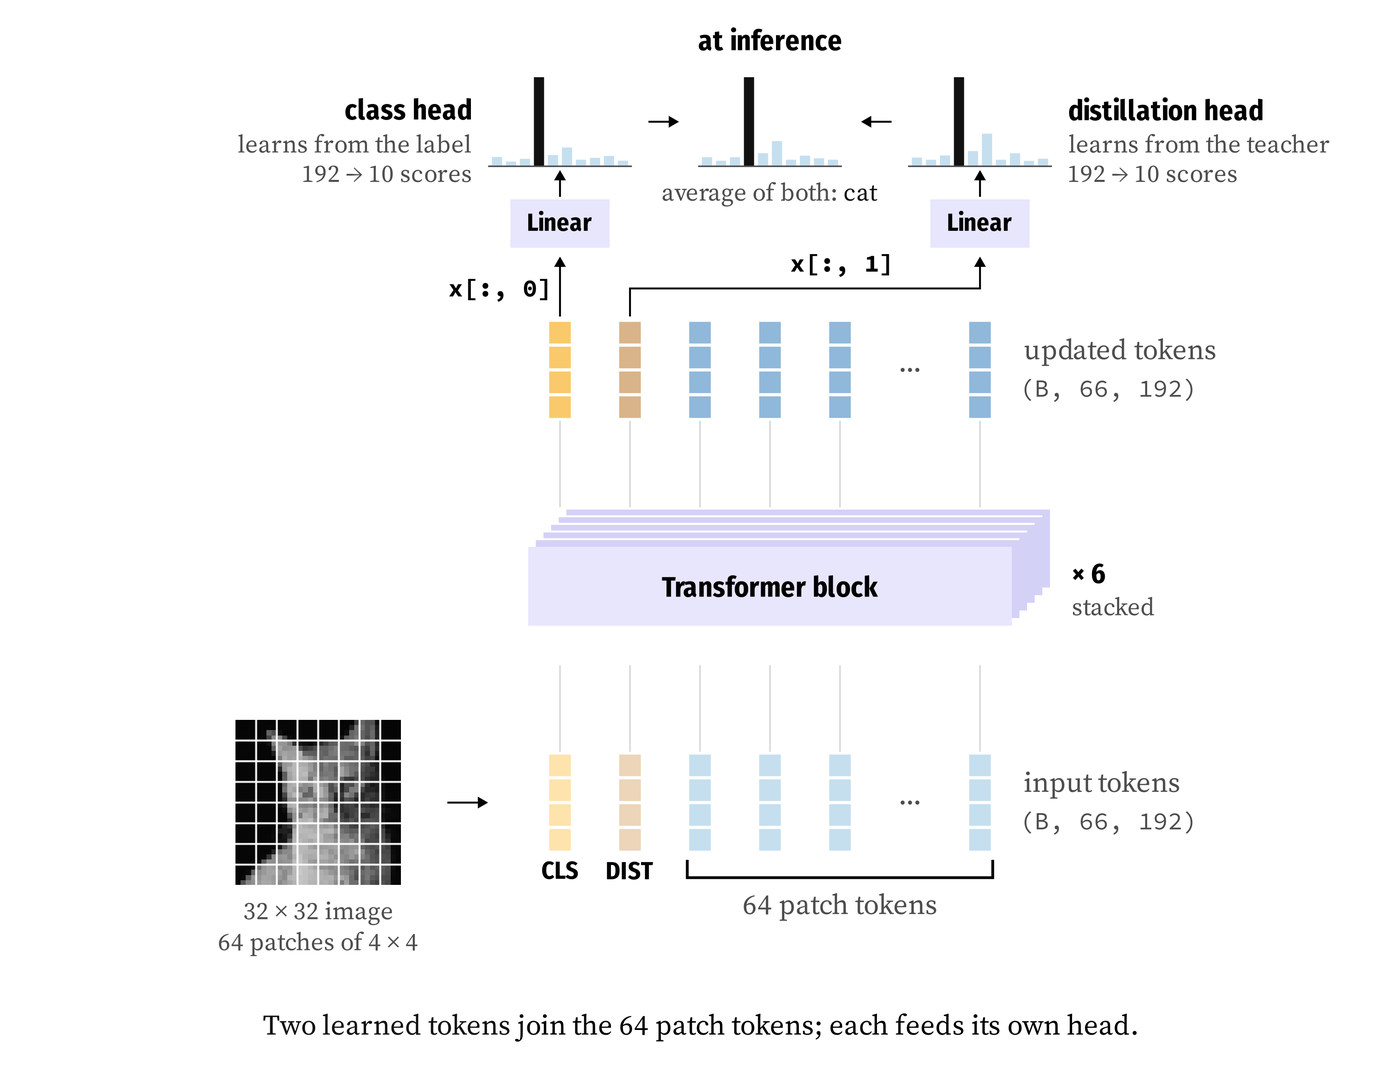

The cell below cuts a real validation image into its 64 patches, row by row. The order of the patches is the order of the tokens.

**In pictures:** what the next cell does.

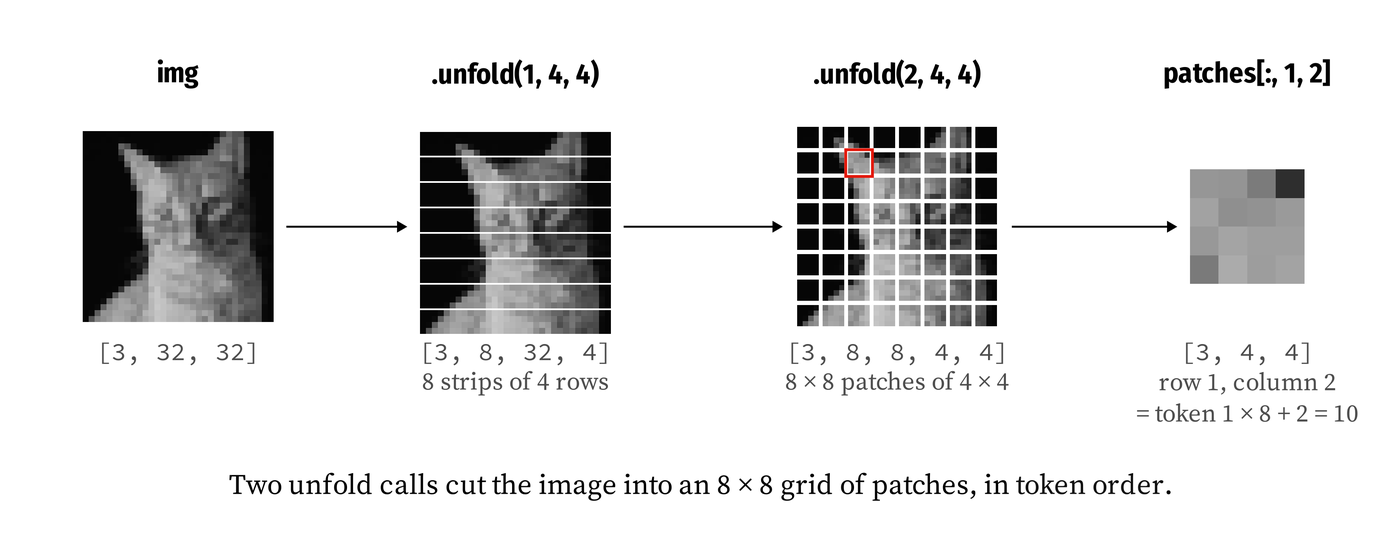

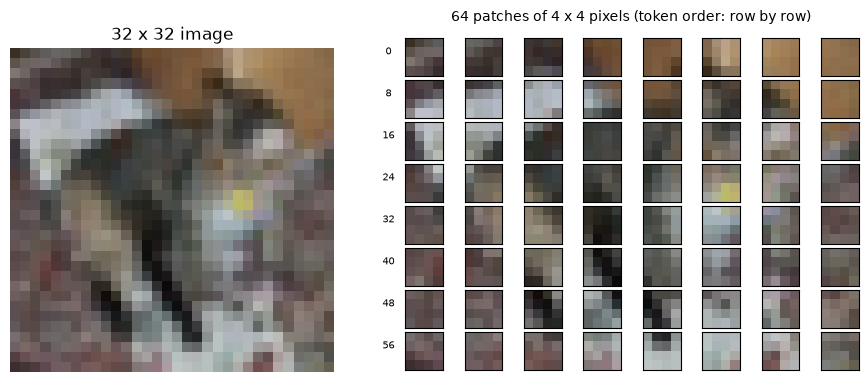

In [6]:
#@title Cut one image into 64 patches
img = val_set[next(i for i in val_idx if targets[i] == class_names.index('cat'))][0]
patches = img.unfold(1, PATCH_SIZE, PATCH_SIZE).unfold(2, PATCH_SIZE, PATCH_SIZE)   # [3, 8, 8, 4, 4]
grid = IMG_SIZE // PATCH_SIZE
fig = plt.figure(figsize=(9, 4.2))
ax = fig.add_axes([0.02, 0.1, 0.36, 0.8]); ax.imshow(denorm(img)); ax.set_title('32 x 32 image'); ax.axis('off')
for r in range(grid):
    for c in range(grid):
        a = fig.add_axes([0.45 + c * 0.066, 0.82 - r * 0.1, 0.06, 0.09])
        a.imshow(denorm(patches[:, r, c])); a.set_xticks([]); a.set_yticks([])
        if c == 0: a.set_ylabel(f'{r * grid}', rotation=0, labelpad=12, fontsize=7)
fig.text(0.71, 0.95, '64 patches of 4 x 4 pixels (token order: row by row)', ha='center')
plt.show()

## 5. Attention and the transformer block, from scratch

Chapter 2 built these pieces step by step. Here they are again in a compact form. We write them ourselves instead of using `nn.TransformerEncoderLayer` for one reason: in section 13 we want to read the attention weights, and our own `Attention` class can keep them.

```text
x  ->  LayerNorm -> multi-head attention -> + x  ->  LayerNorm -> MLP -> + (shortcut)
       \______________ token mixing ____________/    \_______ per-token update _______/
```

| Piece | What it does |
| --- | --- |
| `qkv` | One linear layer makes queries, keys, and values for all heads at once |
| scores | Each query is compared with every key; dividing by the square root of the head width keeps the softmax well behaved |
| `softmax` | Turns each query's scores into weights that add up to 1 |
| `proj` | Mixes the heads' outputs back into one 192-number vector |
| `Block` | Pre-norm attention and MLP, each wrapped in a residual connection |

**In pictures:** what the next cell does.

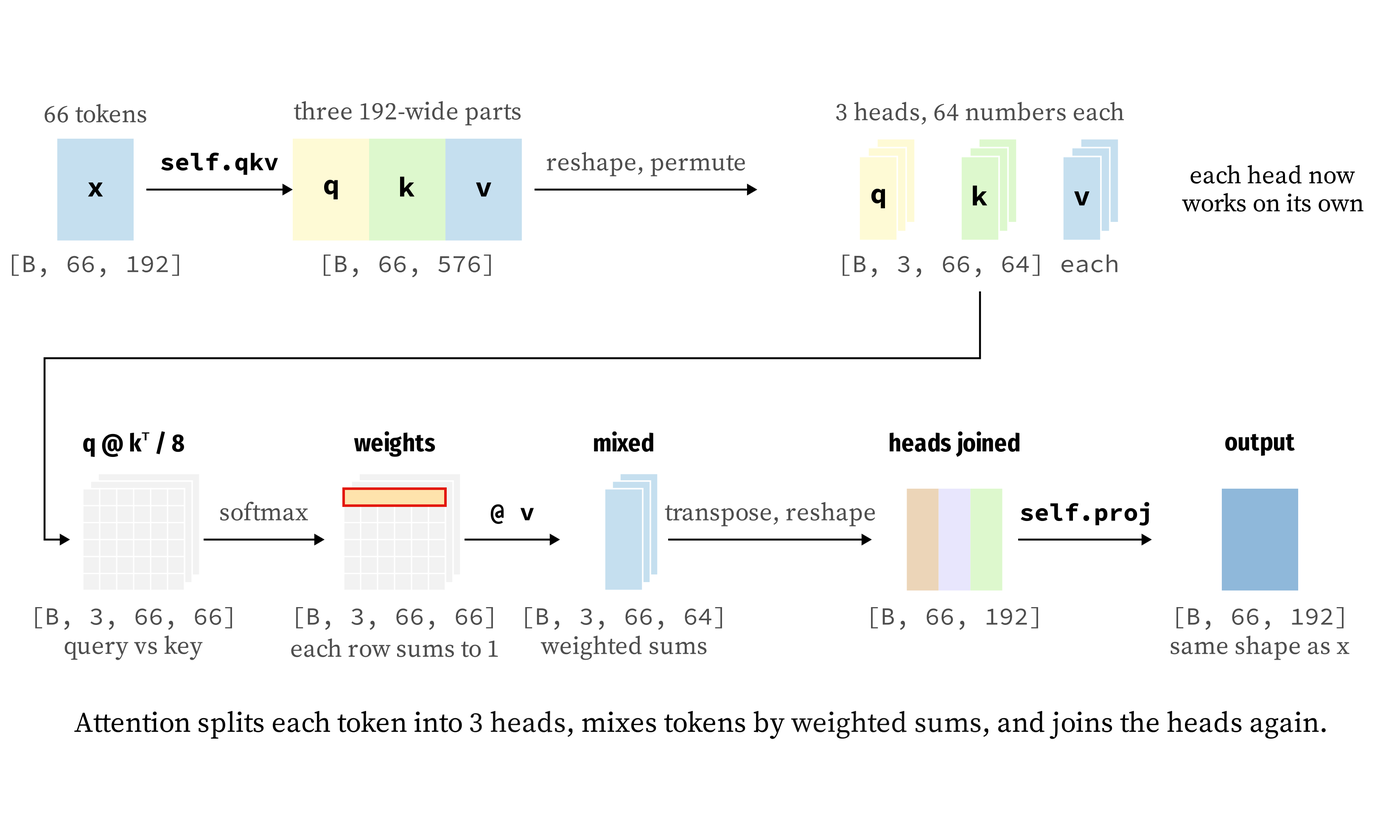
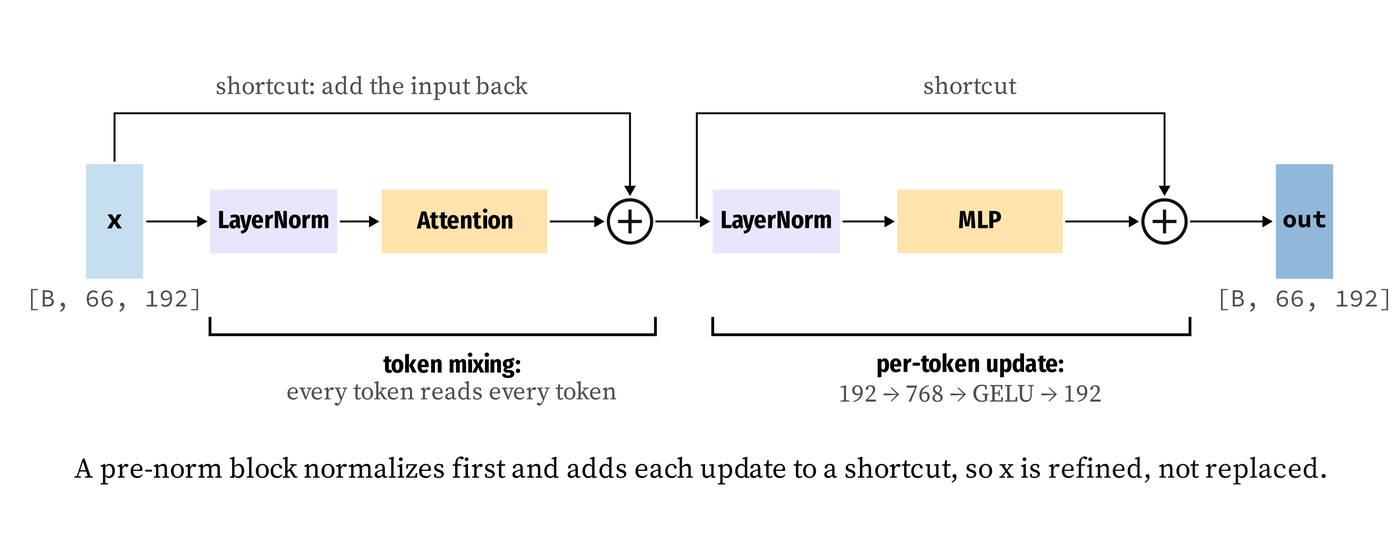

In [7]:
#@title Attention and transformer block
class Attention(nn.Module):
    def __init__(self, dim=EMBED_DIM, heads=HEADS):
        super().__init__()
        self.heads = heads
        # Project queries, keys, and values for all heads in one operation.
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.keep_weights, self.weights = False, None
    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.heads, C // self.heads)
        # Move the Q/K/V axis to the front, then unpack it into three tensors.
        q, k, v = qkv.permute(2, 0, 3, 1, 4)
        scores = (q @ k.transpose(-2, -1)) * q.shape[-1] ** -0.5
        # For each query, turn its scores into weights over the keys.
        weights = scores.softmax(dim=-1)
        if self.keep_weights:
            self.weights = weights.detach()
        # Mix the values within each head, then join the heads side by side.
        mixed = (weights @ v).transpose(1, 2).reshape(B, N, C)
        return self.proj(mixed)

class Block(nn.Module):
    def __init__(self, dim=EMBED_DIM, heads=HEADS):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = Attention(dim, heads)
        self.mlp = nn.Sequential(nn.Linear(dim, MLP_RATIO * dim), nn.GELU(),
                                 nn.Linear(MLP_RATIO * dim, dim))
    def forward(self, x):
        # Normalize the input for attention, then add its update to the original tokens.
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

## 6. The DeiT student

The student is a ViT with three additions: a `dist` token, one more positional embedding for it, and a second linear head. With `distill=False` the same class builds the plain ViT we use for S0.

| Mode | `forward` returns | Used for |
| --- | --- | --- |
| `model.train()` | `(cls_out, dist_out)`, two score vectors | two losses, one per head |
| `model.eval()` | `(cls_out + dist_out) / 2` | prediction: the two heads vote together |

`heads` always returns both score vectors, so the analysis sections can score each head on its own.

**In pictures:** what the next cell does.

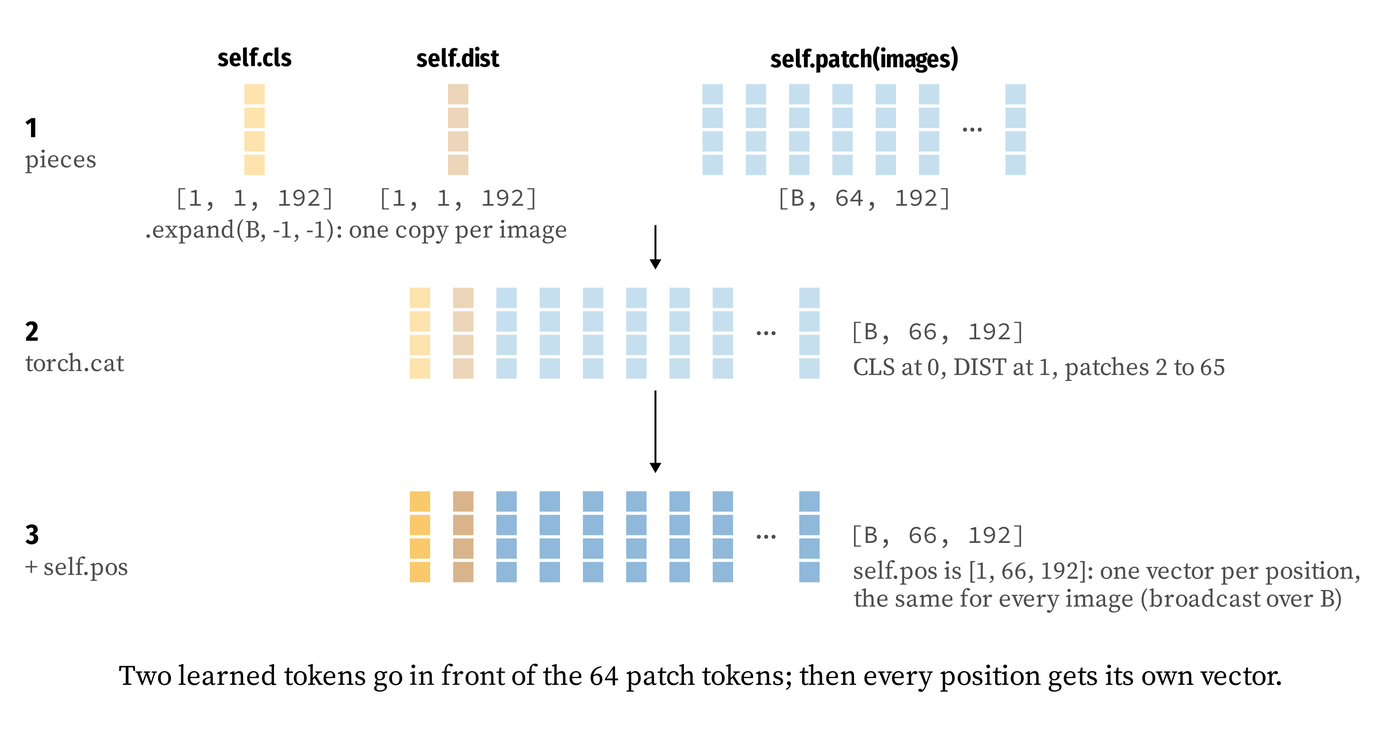

In [8]:
#@title The DeiT student
class PatchEmbed(nn.Module):
    def __init__(self):
        super().__init__()
        # Use a patch-sized kernel and stride to project each non-overlapping patch into
        # a token.
        self.proj = nn.Conv2d(CHANNELS, EMBED_DIM, PATCH_SIZE, PATCH_SIZE)
        self.n = (IMG_SIZE // PATCH_SIZE) ** 2
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)                     # [B, 64, 192]

class DeiTStudent(nn.Module):
    def __init__(self, distill=True):
        super().__init__()
        self.distill = distill
        self.patch = PatchEmbed()
        n_special = 2 if distill else 1
        self.cls = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        # Add a second learned token when distillation is enabled.
        self.dist = nn.Parameter(torch.zeros(1, 1, EMBED_DIM)) if distill else None
        self.pos = nn.Parameter(torch.zeros(1, self.patch.n + n_special, EMBED_DIM))
        self.blocks = nn.ModuleList([Block() for _ in range(DEPTH)])
        self.norm = nn.LayerNorm(EMBED_DIM)
        self.cls_head = nn.Linear(EMBED_DIM, CLASSES)
        self.dist_head = nn.Linear(EMBED_DIM, CLASSES) if distill else None
        self.apply(init_weights)
        for p in [self.cls, self.pos] + ([self.dist] if distill else []):
            nn.init.trunc_normal_(p, std=0.02)
    def tokens(self, images):
        patches = self.patch(images)
        B = patches.shape[0]
        special = [self.cls.expand(B, -1, -1)]
        if self.distill:
            special.append(self.dist.expand(B, -1, -1))
        # Prepend the special tokens to the patches, then add position information.
        return torch.cat(special + [patches], dim=1) + self.pos
    def encode(self, images):
        x = self.tokens(images)
        for block in self.blocks:
            x = block(x)
        return self.norm(x)
    def heads(self, images):
        x = self.encode(images)
        # The class head reads the CLS token at position 0.
        cls_out = self.cls_head(x[:, 0])
        # The distillation head reads the DIST token at position 1.
        dist_out = self.dist_head(x[:, 1]) if self.distill else None
        return cls_out, dist_out
    def forward(self, images):
        cls_out, dist_out = self.heads(images)
        if not self.distill:
            return cls_out
        if self.training:
            return cls_out, dist_out
        # At evaluation time, average the two heads' class scores.
        return (cls_out + dist_out) / 2

A quick shape check confirms the wiring before we spend any time training.

**In pictures:** what the next cell does.

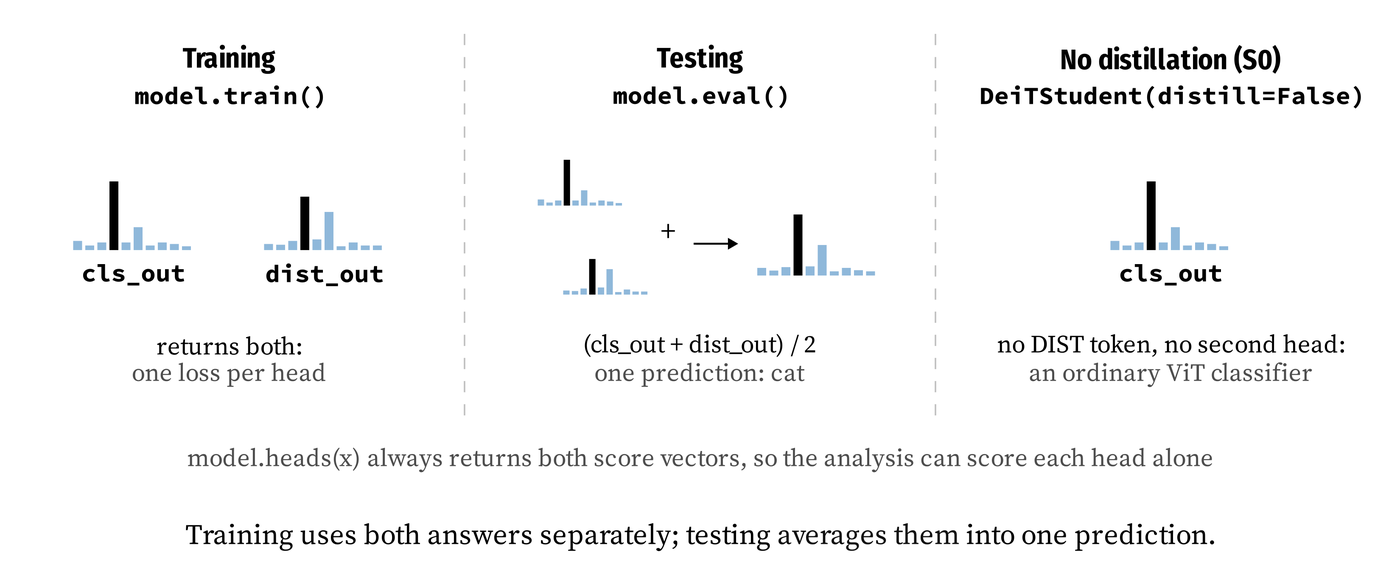

In [9]:
#@title Shape check
x = torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE)
student = DeiTStudent()
print('tokens        :', tuple(student.tokens(x).shape), ' [batch, 2 special + 64 patches, features]')
student.train()
cls_out, dist_out = student(x)
print('train forward :', tuple(cls_out.shape), tuple(dist_out.shape), ' [class head], [distillation head]')
student.eval()
print('eval forward  :', tuple(student(x).shape), ' [average of the two heads]')
print('ViT (S0)      :', tuple(DeiTStudent(distill=False)(x).shape))

tokens        : (2, 66, 192)  [batch, 2 special + 64 patches, features]
train forward : (2, 10) (2, 10)  [class head], [distillation head]
eval forward  : (2, 10)  [average of the two heads]
ViT (S0)      : (2, 10)


## 7. The teacher: a ResNet-18 trained on the same images

DeiT's best results came from a **convolutional** teacher. In the paper, a CNN teacher that was less accurate than a transformer teacher still produced the better student. The authors' explanation is that the CNN passes on its built-in assumptions about images through its predictions. The student does not copy the CNN's layers, only its answers.

Our teacher is the standard ResNet-18 with one change for small images: the first layer is a 3 x 3 convolution with stride 1 and there is no max-pooling, so a 32 x 32 image is not shrunk to 8 x 8 before the first block. This is the common CIFAR version of ResNet-18.

| Stage | Output for one image | Blocks |
| --- | --- | --- |
| Stem | 64 x 32 x 32 | one 3 x 3 convolution |
| Layer 1 | 64 x 32 x 32 | 2 basic blocks |
| Layer 2 | 128 x 16 x 16 | 2 basic blocks |
| Layer 3 | 256 x 8 x 8 | 2 basic blocks |
| Layer 4 | 512 x 4 x 4 | 2 basic blocks |
| Head | 10 scores | average pooling and a linear layer |

**In pictures:** what the next cell does.

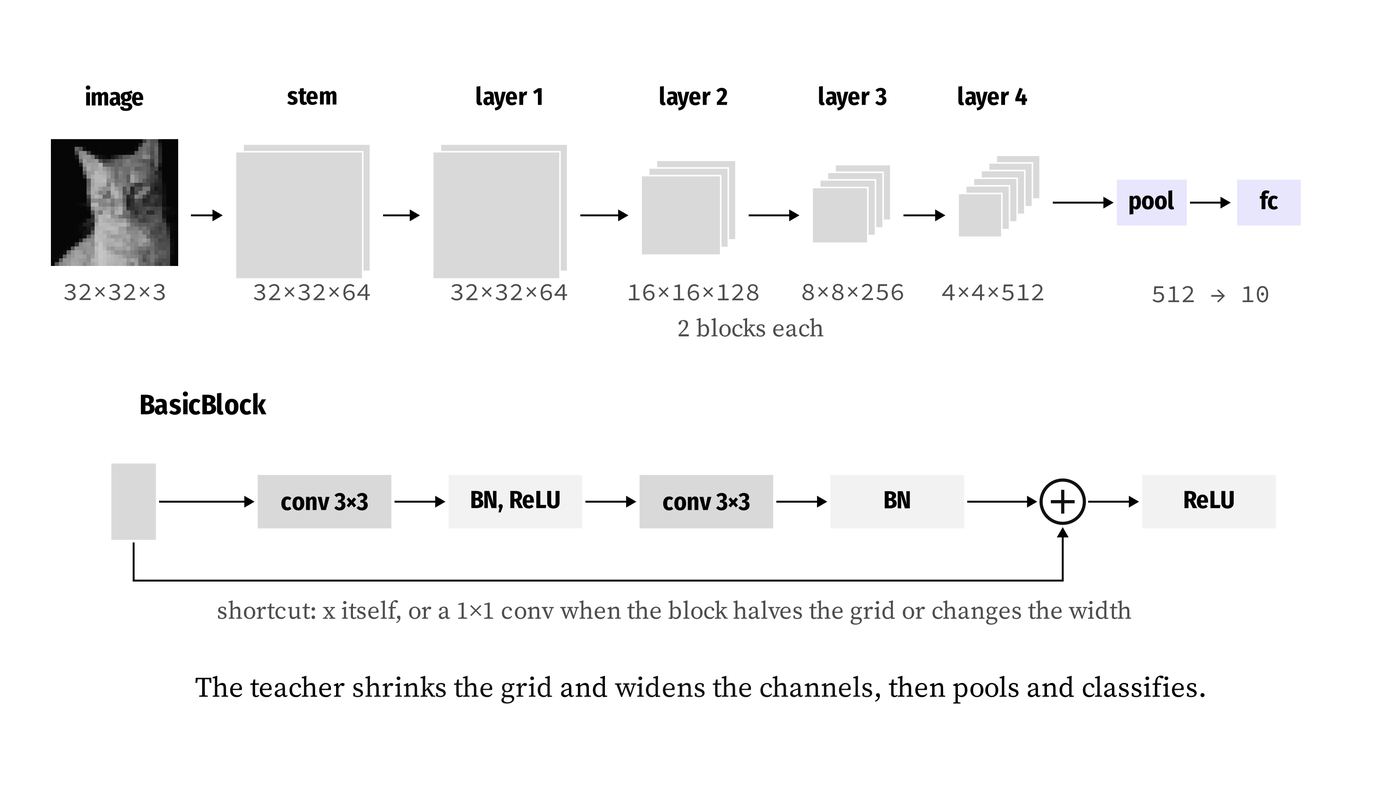

In [10]:
#@title ResNet-18 for 32 x 32 images
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Sequential()
        # Project the shortcut when the block changes the grid size or channel count.
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))
    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        return F.relu(y + self.shortcut(x))

class ResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        # Keep the full 32 x 32 grid in the stem; do not add max-pooling.
        self.stem = nn.Sequential(nn.Conv2d(CHANNELS, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
        layers, c_in = [], 64
        for c_out, stride in [(64, 1), (64, 1), (128, 2), (128, 1), (256, 2), (256, 1), (512, 2), (512, 1)]:
            layers.append(BasicBlock(c_in, c_out, stride))
            c_in = c_out
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(512, CLASSES)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

### Size and compute before training

Parameters tell you how much memory the weights need. GMACs, billions of multiply-accumulate operations per image, estimate the work of one forward pass. Both can be measured before any training.

**In pictures:** what the next cell does.

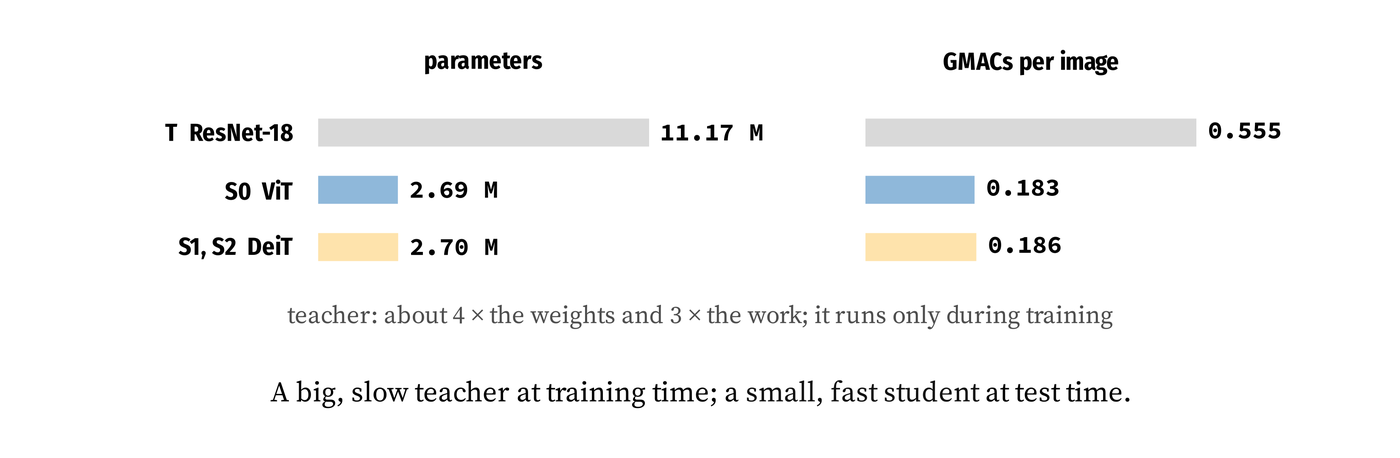

In [11]:
#@title Parameters and GMACs
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def count_gmacs(model):
    model.eval()
    with FlopCounterMode(display=False) as counter:
        model(torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE))
    return counter.get_total_flops() / 2e9                                 # 1 MAC = 2 FLOPs

SIZES = {}
for name, make in [('T  ResNet-18 teacher', ResNet18),
                   ('S0 ViT, class token only', lambda: DeiTStudent(distill=False)),
                   ('S1/S2 DeiT student', DeiTStudent)]:
    m = make()
    SIZES[name] = (count_params(m), count_gmacs(m))
    print(f'{name:26s} {SIZES[name][0] / 1e6:6.2f}M params   {SIZES[name][1]:.3f} GMACs per image')

T  ResNet-18 teacher        11.17M params   0.555 GMACs per image
S0 ViT, class token only     2.69M params   0.183 GMACs per image
S1/S2 DeiT student           2.70M params   0.186 GMACs per image


### What you should see

The teacher is about four times larger than the student and does about three times more work per image. That is the usual DeiT setup: a big, slow teacher at training time, and a small, fast student at test time. The distillation token and head add fewer than 2,500 parameters to the student.

### Train the teacher

The teacher trains with SGD and a **one-cycle** learning rate: it rises to `TEACHER_LR` and then falls to almost zero. This schedule reaches about 92 to 93% on CIFAR-10 in 15 epochs (92.8% validation, 91.5% test in our run). After training we freeze the teacher. It never changes again; it only produces targets.

In [12]:
#@title Train the teacher
def autocast():
    '''Mixed precision on CUDA GPUs; plain float32 on MPS and CPU.'''
    return torch.autocast('cuda', dtype=torch.float16) if device == 'cuda' else nullcontext()

@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast():
            correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    return 100 * correct / total

def train_teacher():
    path = f'{CKPT_DIR}/T_resnet18.pt'
    torch.manual_seed(SEED)
    model = ResNet18().to(device)
    # Load the finished teacher if its checkpoint is already available.
    if os.path.exists(path):
        ckpt = torch.load(path, map_location=device)
        model.load_state_dict(ckpt['model'])
        print('loaded', path)
        return model, ckpt['history']
    opt = torch.optim.SGD(model.parameters(), lr=TEACHER_LR, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, TEACHER_LR, total_steps=TEACHER_EPOCHS * len(teacher_train_dl))
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    history, start = [], time.time()
    for epoch in range(TEACHER_EPOCHS):
        model.train()
        for x, y in teacher_train_dl:
            x, y = x.to(device), y.to(device)
            with autocast():
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
        history.append(accuracy(model, val_dl))
        print(f'teacher epoch {epoch + 1:2d}/{TEACHER_EPOCHS}  val {history[-1]:5.1f}%  ({time.time() - start:.0f}s)')
    torch.save({'model': model.state_dict(), 'history': history, 'minutes': (time.time() - start) / 60}, path)
    return model, history

teacher, teacher_history = train_teacher()
# Use fixed batch-normalization statistics and disable gradients for the teacher's
# weights.
teacher.eval().requires_grad_(False)
teacher_val = accuracy(teacher, val_dl)
print(f'teacher validation accuracy: {teacher_val:.1f}%')

teacher epoch  1/15  val  54.2%  (17s)
teacher epoch  2/15  val  68.5%  (33s)
teacher epoch  3/15  val  76.0%  (48s)
teacher epoch  4/15  val  74.9%  (63s)
teacher epoch  5/15  val  74.4%  (78s)
teacher epoch  6/15  val  82.2%  (94s)
teacher epoch  7/15  val  83.9%  (109s)
teacher epoch  8/15  val  81.8%  (125s)
teacher epoch  9/15  val  83.5%  (140s)
teacher epoch 10/15  val  84.3%  (155s)
teacher epoch 11/15  val  87.4%  (171s)
teacher epoch 12/15  val  88.7%  (186s)
teacher epoch 13/15  val  91.3%  (201s)
teacher epoch 14/15  val  92.8%  (217s)
teacher epoch 15/15  val  92.8%  (232s)
teacher validation accuracy: 92.8%


## 8. Hard and soft distillation

Each DeiT student has two heads, so it gets two losses. The class head always learns from the dataset label. The distillation head learns from the teacher in one of two ways.

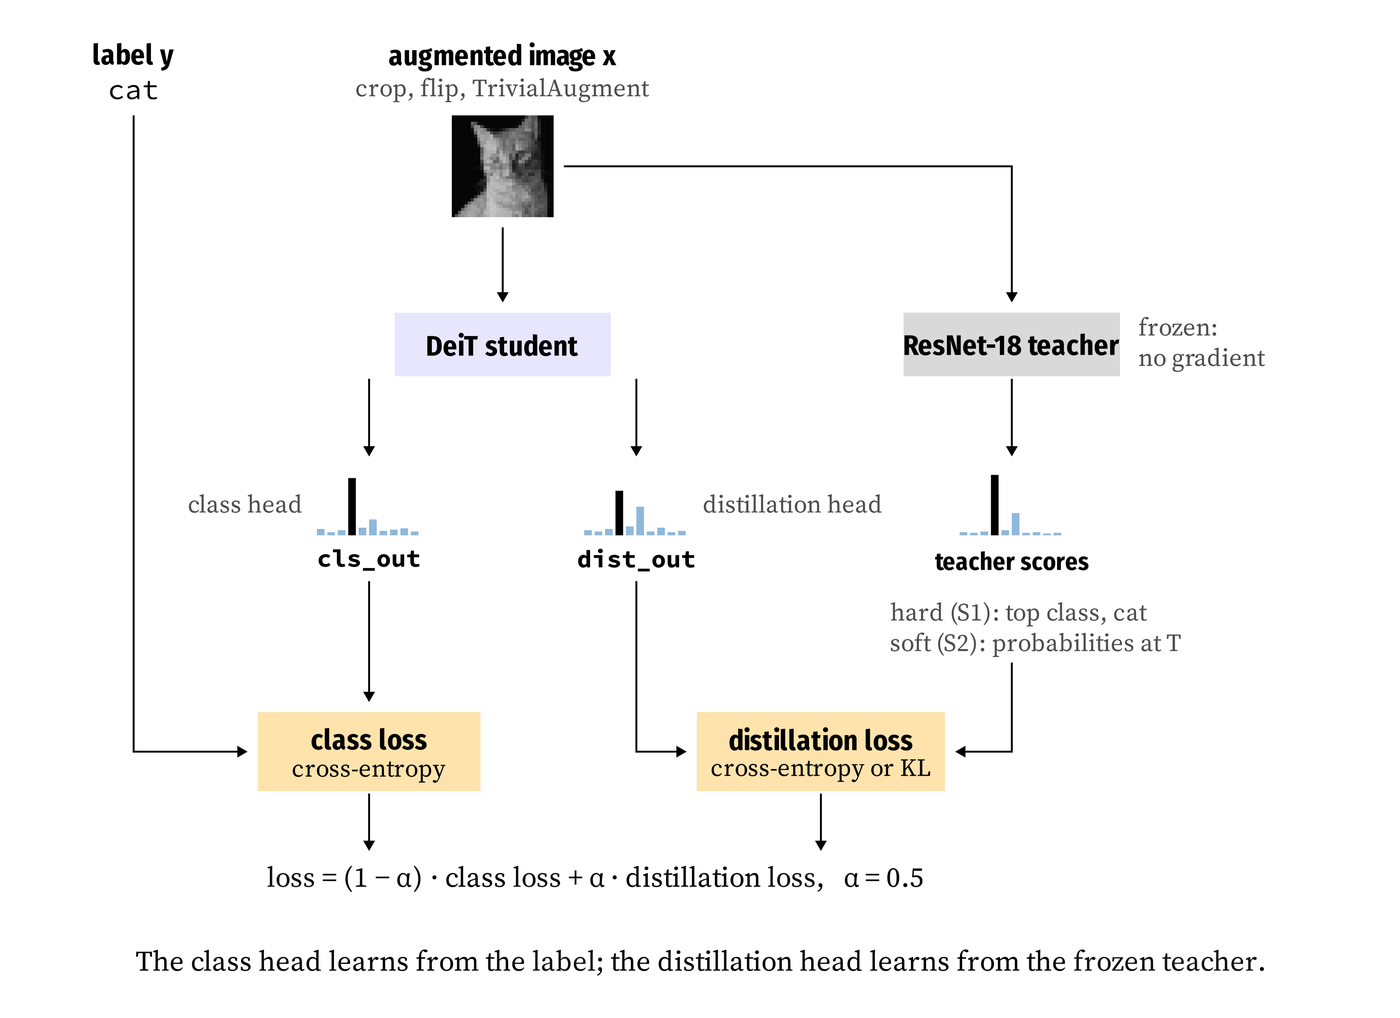

| | Hard distillation (S1) | Soft distillation (S2) |
| --- | --- | --- |
| Teacher target | its top class, `argmax` | its full probability list, softened by temperature $T$ |
| Distillation loss | cross-entropy | KL divergence, scaled by $T^2$ |
| Extra settings | none | the temperature |
| DeiT paper | the better choice for DeiT | close, slightly worse |

With $z_{cls}$ and $z_{dist}$ the two heads' scores, $z_t$ the teacher's scores, $y$ the label, and $\psi$ the softmax:

$$
\mathcal{L}_{hard} = (1-\alpha)\,\mathrm{CE}(\psi(z_{cls}), y) + \alpha\,\mathrm{CE}(\psi(z_{dist}), \operatorname{argmax} z_t)
$$

$$
\mathcal{L}_{soft} = (1-\alpha)\,\mathrm{CE}(\psi(z_{cls}), y) + \alpha\,T^2\,\mathrm{KL}\big(\psi(z_t/T)\,\|\,\psi(z_{dist}/T)\big)
$$

We use $\alpha = 0.5$, so each head's loss counts equally. The teacher sees **the same augmented image** as the student. When a random crop cuts away most of the cat, the teacher's answer describes what is actually left in the crop, which can be more useful than the original label.

### A toy example first

Before the real loss, let's compute both targets by hand for one image. The teacher is fairly sure it is a cat, but also sees something dog-like.

**In pictures:** what the next cell does.

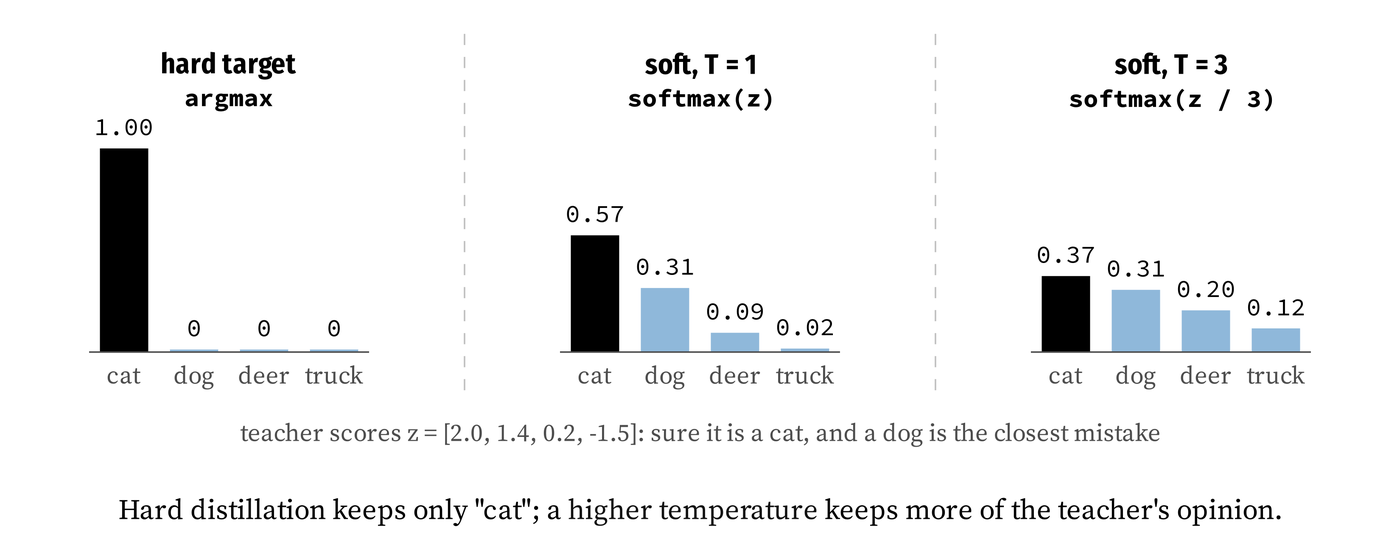

In [13]:
#@title Hard and soft targets on a toy example
names = ['cat', 'dog', 'deer', 'truck']
teacher_scores = torch.tensor([[2.0, 1.4, 0.2, -1.5]])
student_scores = torch.tensor([[0.8, 1.1, 0.3, -0.2]])                    # the student currently prefers dog

hard = teacher_scores.argmax(1)
print('hard target           :', names[hard.item()])
for T in (1, 3):
    probs = (teacher_scores / T).softmax(-1)[0]
    print(f'soft target, T = {T}    :', '  '.join(f'{n} {p:.2f}' for n, p in zip(names, probs)))

hard_loss = F.cross_entropy(student_scores, hard)
T = 3.0
soft_loss = F.kl_div((student_scores / T).log_softmax(-1), (teacher_scores / T).log_softmax(-1),
                     reduction='batchmean', log_target=True) * T * T
print(f'\nhard loss {hard_loss:.3f}   soft loss {soft_loss:.3f}')

hard target           : cat
soft target, T = 1    : cat 0.57  dog 0.31  deer 0.09  truck 0.02
soft target, T = 3    : cat 0.37  dog 0.31  deer 0.20  truck 0.12

hard loss 1.201   soft loss 0.333


The hard target is simply "cat". The soft target at $T = 3$ keeps the teacher's opinion that a dog is a much closer mistake than a truck. That extra information is what section 4.1.1 calls dark knowledge. Raising the temperature spreads the probability more evenly and makes the second and third choices easier to learn from; multiplying by $T^2$ keeps the gradient at a sensible size.

### The real loss

**In pictures:** what the next cell does.

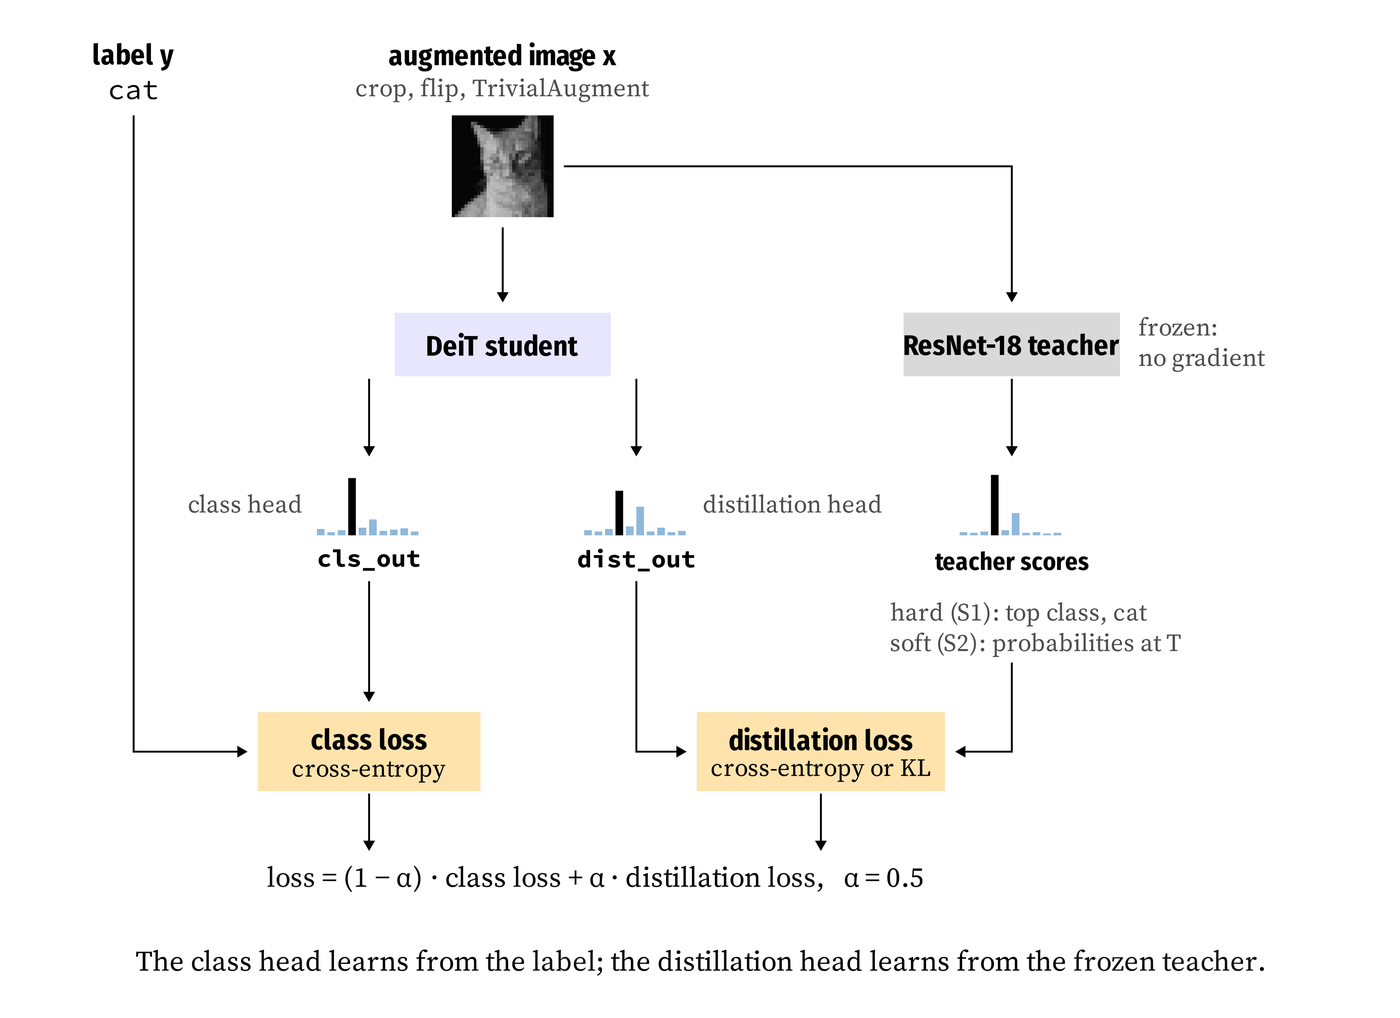

In [14]:
#@title The student's training loss
def student_loss(model, x, y, mode):
    if mode == 'none':
        # The plain ViT student learns from the dataset labels only.
        return F.cross_entropy(model(x), y, label_smoothing=LABEL_SMOOTHING)
    cls_out, dist_out = model(x)
    with torch.no_grad():
        # Score the same augmented images with the frozen teacher, without a gradient
        # graph.
        teacher_scores = teacher(x)
    class_loss = F.cross_entropy(cls_out, y, label_smoothing=LABEL_SMOOTHING)
    if mode == 'hard':
        # Use the teacher's top class as the hard target for the DIST head.
        dist_loss = F.cross_entropy(dist_out, teacher_scores.argmax(dim=1))
    else:
        T = TEMPERATURE
        # Match the teacher's softened probabilities with KL divergence, scaled by T
        # squared.
        dist_loss = F.kl_div((dist_out.float() / T).log_softmax(-1),
                             (teacher_scores.float() / T).log_softmax(-1),
                             reduction='batchmean', log_target=True) * T * T
    # Weight the label loss by 1 - ALPHA and the distillation loss by ALPHA.
    return (1 - ALPHA) * class_loss + ALPHA * dist_loss

## 9. The training loop

All three students share one loop. Only `mode` changes.

1. Move a batch of augmented images and labels to the device.
2. Compute `student_loss` for this run's mode (in mixed precision on CUDA GPUs).
3. Backpropagate, clip the gradient norm to 1, and take an AdamW step.
4. Update the learning rate: a linear warmup over `WARMUP_EPOCHS`, then a cosine decay to zero.
5. After each epoch, measure validation accuracy of the class head, the distillation head, and their average. Keep the weights from the best epoch.

In [15]:
#@title Training loop
@torch.no_grad()
def evaluate(model, loader):
    '''Accuracy of the class head, the distillation head, and their average.'''
    model.eval()
    hits = {'cls': 0, 'dist': 0, 'avg': 0}
    total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast():
            cls_out, dist_out = model.heads(x)
        avg = cls_out if dist_out is None else (cls_out + dist_out) / 2
        hits['cls'] += (cls_out.argmax(1) == y).sum().item()
        hits['avg'] += (avg.argmax(1) == y).sum().item()
        if dist_out is not None:
            hits['dist'] += (dist_out.argmax(1) == y).sum().item()
        total += y.numel()
    acc = {k: 100 * v / total for k, v in hits.items()}
    if not model.distill:
        acc['dist'] = float('nan')
    return acc

def warmup_cosine(total_steps, warmup_steps):
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))
    return factor

def train_student(key, make_model, mode):
    path = f'{CKPT_DIR}/{key}.pt'
    # Reset the random seed before creating each student.
    torch.manual_seed(SEED)
    model = make_model().to(device)
    if os.path.exists(path):
        ckpt = torch.load(path, map_location=device)
        model.load_state_dict(ckpt['model'])
        print('loaded', path)
        return model, ckpt['history']
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * len(student_train_dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine(steps, WARMUP_EPOCHS * len(student_train_dl)))
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    history, best, best_state, start = [], -1.0, None, time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        for x, y in student_train_dl:
            x, y = x.to(device), y.to(device)
            with autocast():
                loss = student_loss(model, x, y, mode)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            total_loss += loss.item()
        acc = evaluate(model, val_dl)
        history.append({'loss': total_loss / len(student_train_dl), **acc})
        # Keep the weights with the best validation accuracy for the averaged
        # prediction.
        if acc['avg'] > best:
            best = acc['avg']
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f'{key} epoch {epoch + 1:2d}/{EPOCHS}  loss {history[-1]["loss"]:.3f}  '
              f'val avg {acc["avg"]:5.1f}%  cls {acc["cls"]:5.1f}%  dist {acc["dist"]:5.1f}%  ({time.time() - start:.0f}s)')
    model.load_state_dict(best_state)
    torch.save({'model': best_state, 'history': history, 'minutes': (time.time() - start) / 60}, path)
    return model, history

## 10. Train the three students

This is the longest cell. Each line of output is one epoch. `cls` and `dist` are the two heads on their own; `avg` is the DeiT prediction. For S0, `dist` is `nan` because it has no distillation head.

**In pictures:** what the next cell does.

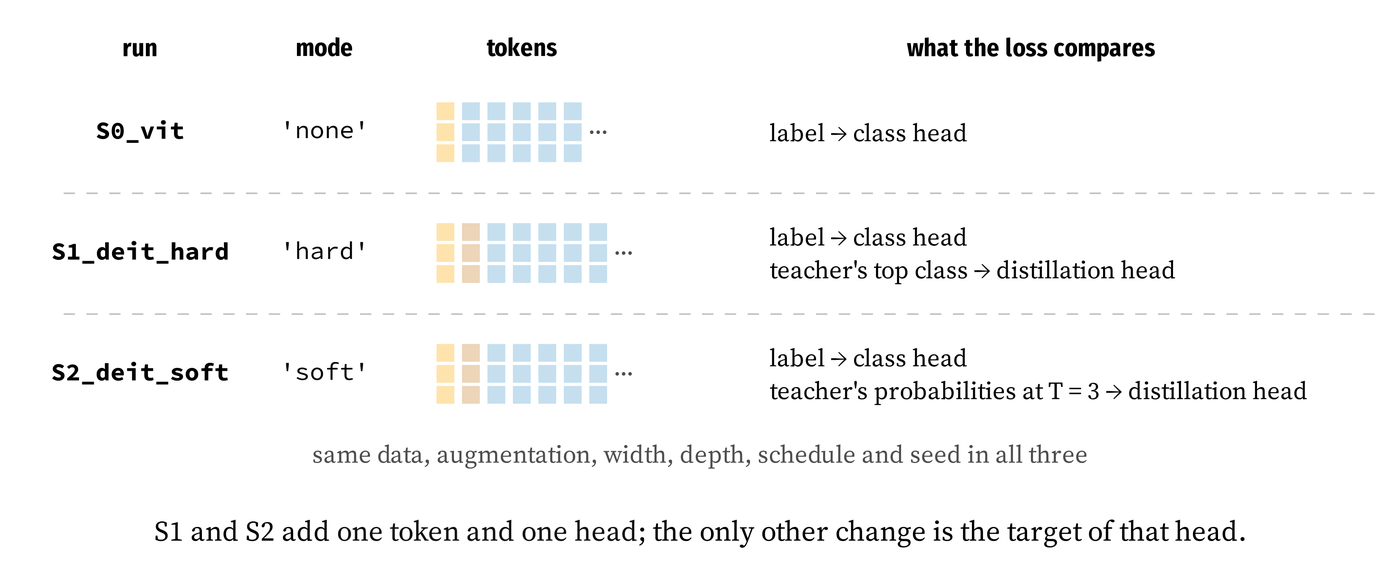

In [16]:
#@title Train S0, S1, and S2
EXPERIMENTS = {
    'S0_vit':       (lambda: DeiTStudent(distill=False), 'none'),
    'S1_deit_hard': (lambda: DeiTStudent(),              'hard'),
    'S2_deit_soft': (lambda: DeiTStudent(),              'soft'),
}
models, histories = {}, {}
for key, (make_model, mode) in EXPERIMENTS.items():
    models[key], histories[key] = train_student(key, make_model, mode)

S0_vit epoch  1/30  loss 2.111  val avg  35.3%  cls  35.3%  dist   nan%  (11s)
S0_vit epoch  2/30  loss 1.942  val avg  42.5%  cls  42.5%  dist   nan%  (22s)
S0_vit epoch  3/30  loss 1.892  val avg  47.6%  cls  47.6%  dist   nan%  (32s)
S0_vit epoch  4/30  loss 1.842  val avg  47.5%  cls  47.5%  dist   nan%  (43s)
S0_vit epoch  5/30  loss 1.779  val avg  51.8%  cls  51.8%  dist   nan%  (53s)
S0_vit epoch  6/30  loss 1.730  val avg  54.5%  cls  54.5%  dist   nan%  (64s)
S0_vit epoch  7/30  loss 1.678  val avg  56.1%  cls  56.1%  dist   nan%  (74s)
S0_vit epoch  8/30  loss 1.648  val avg  58.2%  cls  58.2%  dist   nan%  (85s)
S0_vit epoch  9/30  loss 1.603  val avg  59.8%  cls  59.8%  dist   nan%  (95s)
S0_vit epoch 10/30  loss 1.573  val avg  62.2%  cls  62.2%  dist   nan%  (106s)
S0_vit epoch 11/30  loss 1.530  val avg  65.0%  cls  65.0%  dist   nan%  (117s)
S0_vit epoch 12/30  loss 1.504  val avg  66.1%  cls  66.1%  dist   nan%  (127s)
S0_vit epoch 13/30  loss 1.468  val avg  67.9%  c

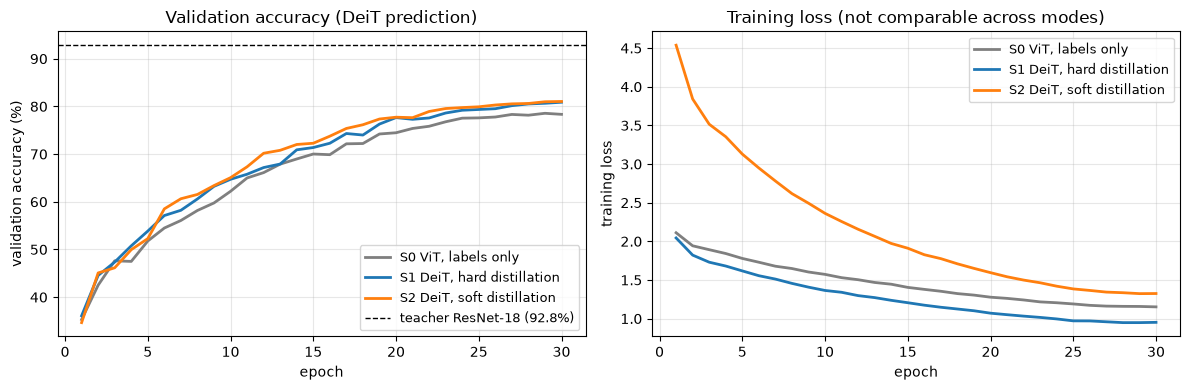

In [17]:
#@title Learning curves
STYLE = {'S0_vit': ('#7f7f7f', 'S0 ViT, labels only'),
         'S1_deit_hard': ('#1f77b4', 'S1 DeiT, hard distillation'),
         'S2_deit_soft': ('#ff7f0e', 'S2 DeiT, soft distillation')}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for key, h in histories.items():
    color, label = STYLE[key]
    epochs = range(1, len(h) + 1)
    a1.plot(epochs, [e['avg'] for e in h], color=color, label=label, lw=2)
    a2.plot(epochs, [e['loss'] for e in h], color=color, label=label, lw=2)
a1.axhline(teacher_val, color='k', ls='--', lw=1, label=f'teacher ResNet-18 ({teacher_val:.1f}%)')
a1.set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy (DeiT prediction)')
a2.set(xlabel='epoch', ylabel='training loss', title='Training loss (not comparable across modes)')
for a in (a1, a2):
    a.grid(alpha=.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

### How to read the curves

- **Left:** the gap between the gray line and the colored lines is what the teacher adds. In our run the three curves stay together for about ten epochs; after that the distilled students pull ahead and finish 2 to 3 points above S0.
- **Right:** the losses are on different scales. S0's loss is one cross-entropy; S1 and S2 average two losses, and the soft loss is a KL divergence. Compare the shape of each curve, not the height.

## 11. Test-set comparison

Now we touch the test set, once. For each student we report the class head alone, the distillation head alone, and their average. We also measure **agreement with the teacher**: the share of test images where the student and the teacher predict the same class, whether right or wrong. The DeiT paper found that distilled students agree with their CNN teacher more often than a ViT trained on labels alone.

**In pictures:** what the next cell does.

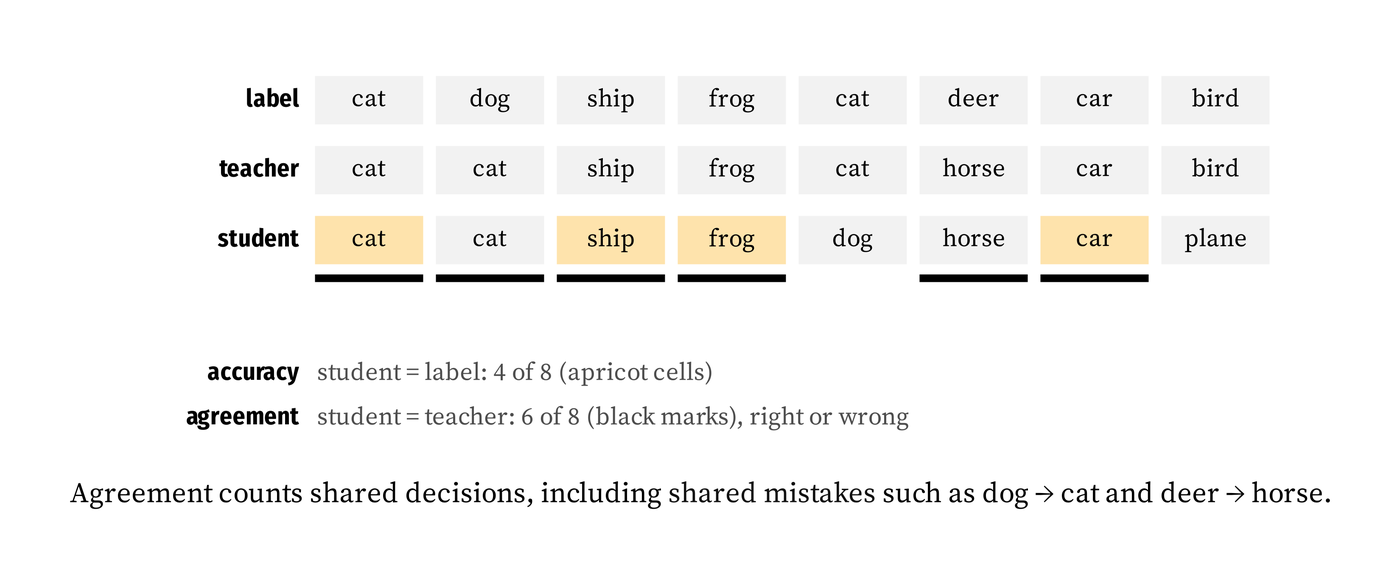

In [18]:
#@title Test accuracy and agreement with the teacher
@torch.no_grad()
def predictions(model, loader):
    model.eval()
    out = {'cls': [], 'dist': [], 'avg': []}
    for x, _ in loader:
        x = x.to(device)
        if isinstance(model, DeiTStudent):
            cls_out, dist_out = model.heads(x)
        else:
            cls_out, dist_out = model(x), None
        avg = cls_out if dist_out is None else (cls_out + dist_out) / 2
        out['cls'].append(cls_out.argmax(1).cpu()); out['avg'].append(avg.argmax(1).cpu())
        if dist_out is not None:
            out['dist'].append(dist_out.argmax(1).cpu())
    return {k: torch.cat(v) for k, v in out.items() if v}

test_labels = torch.tensor(test_set.targets)
teacher_pred = predictions(teacher, test_dl)['avg']
RESULTS = {'T_resnet18': {'params': SIZES['T  ResNet-18 teacher'][0], 'gmacs': SIZES['T  ResNet-18 teacher'][1],
                          'avg': 100 * (teacher_pred == test_labels).float().mean().item()}}
print(f'{"model":24s} {"params":>7s} {"GMACs":>6s} {"class head":>11s} {"dist head":>10s} {"DeiT (avg)":>11s} {"agrees w/ teacher":>18s}')
print(f'{"T  ResNet-18 teacher":24s} {RESULTS["T_resnet18"]["params"] / 1e6:6.2f}M {RESULTS["T_resnet18"]["gmacs"]:6.3f} '
      f'{"":>11s} {"":>10s} {RESULTS["T_resnet18"]["avg"]:10.1f}% {"":>18s}')
test_preds = {}
for key, model in models.items():
    p = test_preds[key] = predictions(model, test_dl)
    acc = {k: 100 * (v == test_labels).float().mean().item() for k, v in p.items()}
    agree = 100 * (p['avg'] == teacher_pred).float().mean().item()
    size = SIZES['S0 ViT, class token only' if key == 'S0_vit' else 'S1/S2 DeiT student']
    RESULTS[key] = {'params': size[0], 'gmacs': size[1], 'cls': acc['cls'], 'dist': acc.get('dist'),
                    'avg': acc['avg'], 'agree': agree, 'minutes': torch.load(f'{CKPT_DIR}/{key}.pt', map_location='cpu')['minutes']}
    dist = f'{acc["dist"]:9.1f}%' if 'dist' in acc else f'{"-":>10s}'
    print(f'{STYLE[key][1]:24.24s} {size[0] / 1e6:6.2f}M {size[1]:6.3f} {acc["cls"]:10.1f}% {dist} {acc["avg"]:10.1f}% {agree:17.1f}%')
json.dump(RESULTS, open(f'{CKPT_DIR}/results.json', 'w'), indent=1)

model                     params  GMACs  class head  dist head  DeiT (avg)  agrees w/ teacher
T  ResNet-18 teacher      11.17M  0.555                              91.5%                   
S0 ViT, labels only        2.69M  0.183       78.1%          -       78.1%              78.3%
S1 DeiT, hard distillati   2.70M  0.186       79.8%      80.3%       80.1%              80.4%
S2 DeiT, soft distillati   2.70M  0.186       80.7%      80.9%       80.7%              81.6%


### Reading the table

| Column | What to look for |
| --- | --- |
| **class head** | Even the class head, which never sees the teacher, improves in S1 and S2. Both heads share the encoder, so the teacher's influence reaches every token. |
| **dist head** | The head trained on the teacher is usually the better single head. |
| **DeiT (avg)** | Averaging the two heads lands close to the better head. In our run it was slightly below the distillation head. |
| **agrees w/ teacher** | Distilled students copy more of the teacher's decisions, including some of its mistakes. |

**In our run:** the distillation head beat the class head in both S1 (80.3% against 79.8%) and S2 (80.9% against 80.7%). Agreement with the teacher rose from 78.3% (S0) to 80.4% (S1) and 81.6% (S2).

## 12. Are the two tokens learning the same thing?

If the class token and the distillation token ended up identical, the second token would be pointless. The DeiT paper measured the cosine similarity between them: about 0.06 at the input, which means nearly unrelated, rising to 0.93 after the last block, which means similar but not identical. Let's measure the same thing in our students, block by block.

S1_deit_hard: input 0.33 -> after block 6 0.96
S2_deit_soft: input 0.38 -> after block 6 0.96


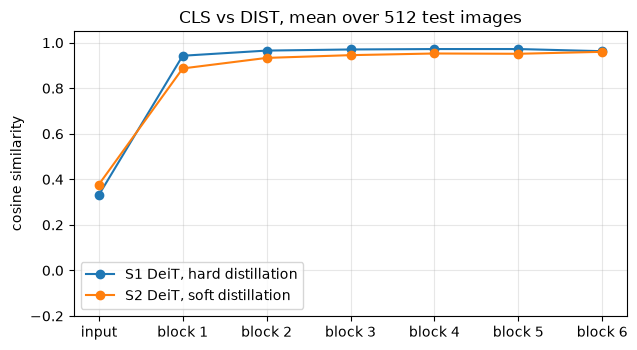

In [19]:
#@title Cosine similarity of CLS and DIST through the blocks
@torch.no_grad()
def token_similarity(model, images):
    model.eval()
    x = model.tokens(images)
    # Compare CLS and DIST after adding positions, before any block. These two input
    # tokens are still the same across images.
    sims = [F.cosine_similarity(x[:, 0], x[:, 1], dim=-1).mean().item()]
    for block in model.blocks:
        x = block(x)
        sims.append(F.cosine_similarity(x[:, 0], x[:, 1], dim=-1).mean().item())
    return sims

probe = torch.stack([test_set[i][0] for i in range(512)]).to(device)
plt.figure(figsize=(6.5, 3.6))
for key in ['S1_deit_hard', 'S2_deit_soft']:
    sims = token_similarity(models[key], probe)
    plt.plot(range(len(sims)), sims, marker='o', color=STYLE[key][0], label=STYLE[key][1])
    print(f'{key}: input {sims[0]:.2f} -> after block {DEPTH} {sims[-1]:.2f}')
plt.xticks(range(DEPTH + 1), ['input'] + [f'block {i}' for i in range(1, DEPTH + 1)])
plt.ylabel('cosine similarity'); plt.ylim(-0.2, 1.05); plt.grid(alpha=.3); plt.legend()
plt.title('CLS vs DIST, mean over 512 test images'); plt.tight_layout(); plt.show()

In our run the similarity rose from 0.33 (S1) and 0.38 (S2) at the input to 0.96 after the last block, close to the paper's 0.93. The two tokens start apart, and the blocks pull them together, because both must end up describing the same image. They do not become identical: the remaining difference is the part of the teacher's view that the label alone does not teach.

## 13. Where do the tokens look?

Each row of an attention matrix says how much one token reads from every other token. We read the last block's rows for **CLS** (position 0) and **DIST** (position 1), keep the 64 entries that point at patch tokens, average the three heads, and draw them as an 8 x 8 map over the image. Brighter squares are patches the token reads more.

**In pictures:** what the next cell does.

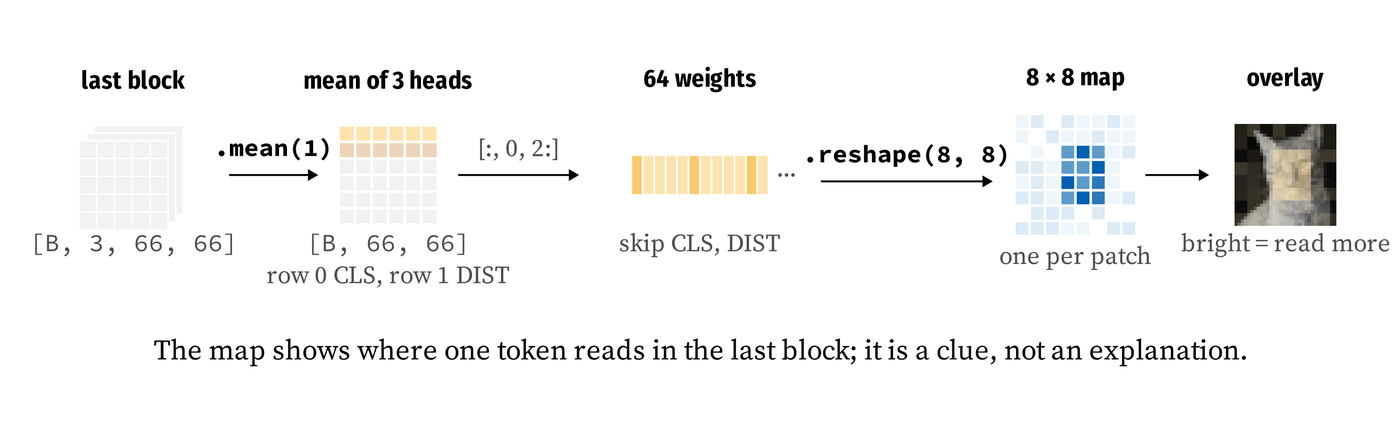

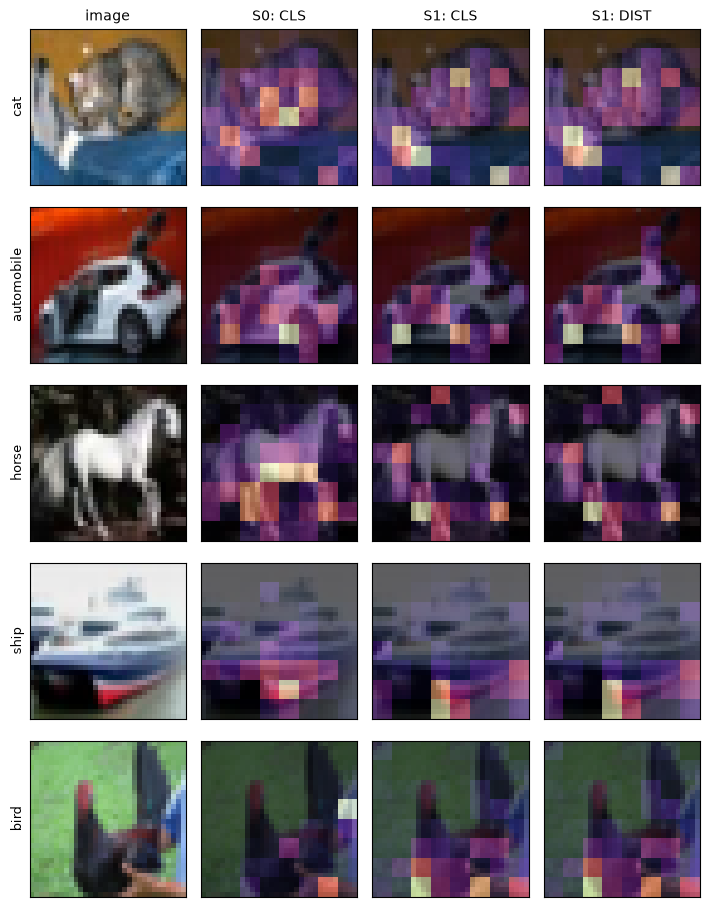

In [20]:
#@title Attention maps of the class and distillation tokens
@torch.no_grad()
def last_block_attention(model, images):
    attn = model.blocks[-1].attn
    attn.keep_weights = True
    model.eval(); model.encode(images)
    attn.keep_weights = False
    w = attn.weights.mean(1)                                               # [B, N, N], averaged over heads
    first = 2 if model.distill else 1
    maps = [w[:, row, first:].reshape(-1, 8, 8) for row in range(first)]  # rows for CLS (and DIST)
    return [m / m.amax(dim=(1, 2), keepdim=True) for m in maps]

pick = [next(i for i in range(len(test_set)) if test_set.targets[i] == c) for c in [3, 1, 7, 8, 2]]
images = torch.stack([test_set[i][0] for i in pick]).to(device)
s0_cls, = last_block_attention(models['S0_vit'], images)
s1_cls, s1_dist = last_block_attention(models['S1_deit_hard'], images)
cols = [('image', None), ('S0: CLS', s0_cls), ('S1: CLS', s1_cls), ('S1: DIST', s1_dist)]
fig, axes = plt.subplots(len(pick), 4, figsize=(7.2, 1.85 * len(pick)))
for r, i in enumerate(pick):
    for c, (title, maps) in enumerate(cols):
        ax = axes[r, c]
        ax.imshow(denorm(test_set[i][0]))
        if maps is not None:
            ax.imshow(maps[r].float().cpu(), cmap='magma', alpha=.6, extent=(-.5, 31.5, 31.5, -.5), interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(title, fontsize=10)
        if c == 0: ax.set_ylabel(class_names[test_set.targets[i]], fontsize=9)
plt.tight_layout(); plt.show()

Attention maps are a rough guide, not an explanation: they show where a token reads in one block, not why the model decided. Still, two patterns are worth checking in your run. First, do CLS and DIST in S1 read from different places? Second, does the distilled student's attention sit more on the object than S0's, which has only the labels to go on?

## 14. What the teacher changes

The teacher scores the **augmented** image. Random crops, flips, and TrivialAugment can remove or distort the object, and then the teacher's answer can differ from the dataset label. The cell below runs the teacher on a few batches of augmented training images, counts how often its top class disagrees with the label, and shows some of those images.

**In pictures:** what the next cell does.

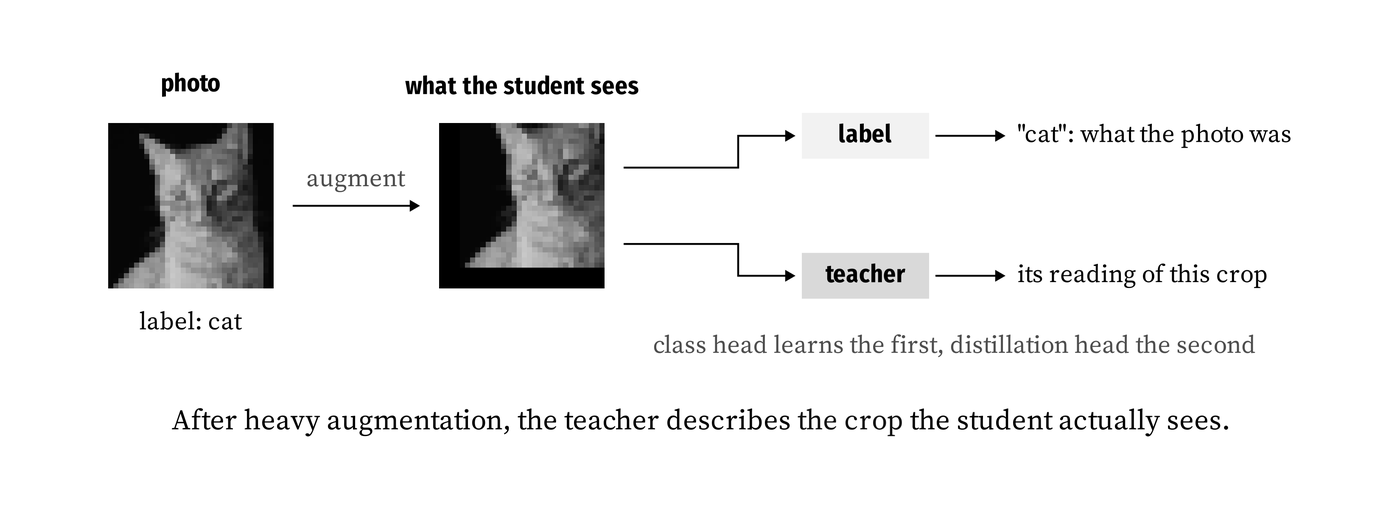

teacher top class differs from the label on 24.7% of 2,048 augmented training images


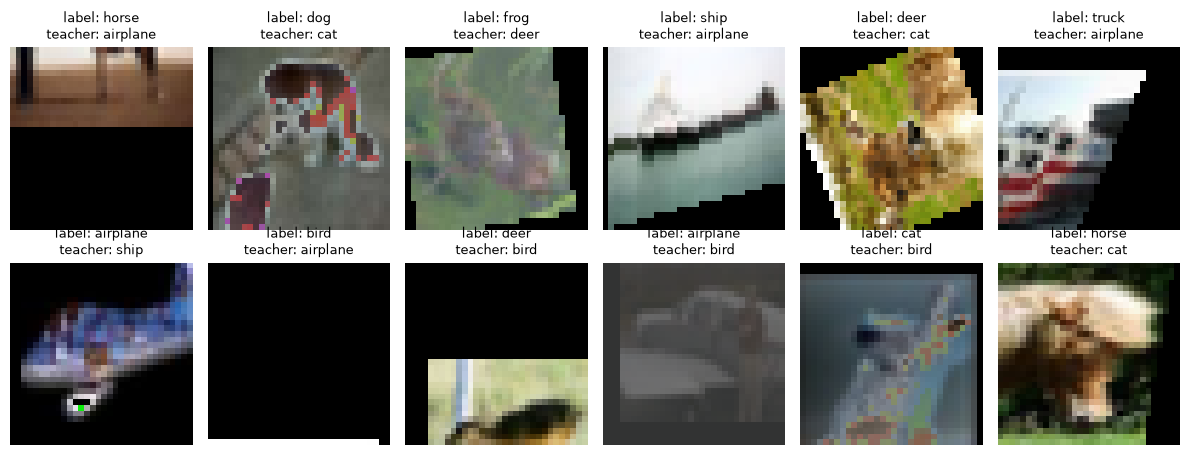

In [21]:
#@title When the teacher disagrees with the label
shown, disagree, seen = [], 0, 0
for b, (x, y) in enumerate(student_train_dl):
    with torch.no_grad():
        t = teacher(x.to(device)).argmax(1).cpu()
    disagree += (t != y).sum().item(); seen += y.numel()
    shown += [(x[i], y[i].item(), t[i].item()) for i in torch.nonzero(t != y).flatten()][:12 - len(shown)]
    if b == 15:
        break
print(f'teacher top class differs from the label on {100 * disagree / seen:.1f}% of {seen:,} augmented training images')
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for ax, (img, y, t) in zip(axes.flat, shown):
    ax.imshow(denorm(img)); ax.axis('off')
    ax.set_title(f'label: {class_names[y]}\nteacher: {class_names[t]}', fontsize=9)
plt.tight_layout(); plt.show()

In our run the teacher's top class differed from the label on 24.7% of the augmented training images. Some of these images are hard to name even for a person. In those cases the label says what the photo was before augmentation, while the teacher describes the crop the student actually sees. Hard distillation gives the student both: the label through the class token, and the teacher's reading through the distillation token.

Finally, which classes gain the most from the teacher? The chart compares per-class test accuracy of S1 and S0.

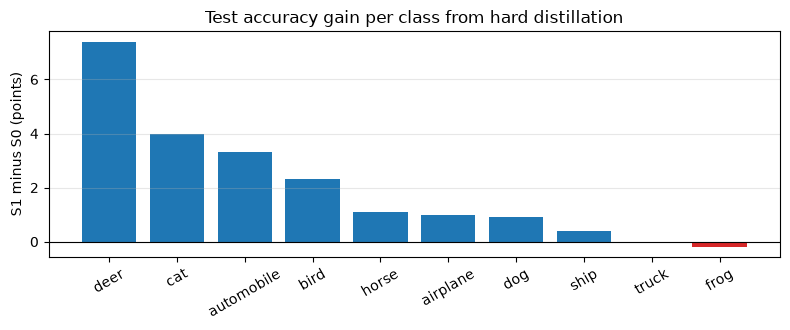

In [22]:
#@title Per-class gain from distillation
per_class = {}
for key in ['S0_vit', 'S1_deit_hard']:
    hit = (test_preds[key]['avg'] == test_labels).float()
    per_class[key] = torch.stack([hit[test_labels == c].mean() for c in range(CLASSES)]) * 100
gain = per_class['S1_deit_hard'] - per_class['S0_vit']
order_c = torch.argsort(gain, descending=True)
plt.figure(figsize=(8, 3.4))
plt.bar([class_names[c] for c in order_c], gain[order_c], color=['#1f77b4' if g >= 0 else '#d62728' for g in gain[order_c]])
plt.axhline(0, color='k', lw=.8); plt.ylabel('S1 minus S0 (points)')
plt.title('Test accuracy gain per class from hard distillation'); plt.xticks(rotation=30); plt.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

## 15. Conclusions and next experiments

### What this notebook demonstrates

| Comparison | Our numbers (test) | Lesson |
| --- | --- | --- |
| S0 vs S1 | 78.1% vs 80.1% | The distillation token adds 2 points at the same size and test-time cost |
| S1 vs S2 | 80.1% vs 80.7% | Hard and soft distillation are close; one seed cannot separate them |
| Class head, S0 vs S2 | 78.1% vs 80.7% | The teacher's guidance reaches the shared encoder, not only its own head |
| Agreement with the teacher | 78.3% → 81.6% | Distilled students make more of the teacher's decisions |
| Student vs teacher | 80.7% vs 91.5% | A 2.7M-parameter ViT trained for 30 epochs is still far from its CNN teacher |

### Key terms

| Term | Meaning |
| --- | --- |
| **Teacher** | A trained, frozen model whose predictions supervise another model |
| **Student** | The model being trained; here a small ViT |
| **Distillation token** | A second learned token, like the class token, whose output is trained on the teacher's predictions |
| **Hard distillation** | The teacher's top class is the target, trained with cross-entropy |
| **Soft distillation** | The teacher's softened probability list is the target, trained with KL divergence |
| **Temperature** | Divides the scores before softmax; higher values spread the probability more evenly |
| **Inductive bias** | Assumptions built into a model's design, such as a CNN's preference for local patterns |

### Limits of this experiment

- **One seed.** Differences of less than a point between runs can be noise. Rerun with other values of `SEED` before trusting small gaps.
- **Short schedule.** DeiT trains for 300 epochs on ImageNet. Thirty epochs on CIFAR-10 shows the effect, not the ceiling.
- **Small model and small images.** Our student has 6 blocks and 64 tokens. The paper's conclusions are for ImageNet at 224 x 224.
- **Training cost.** Distillation adds the teacher's forward pass to every training step. Test-time cost is unchanged.

### Experiments to try

1. **A transformer teacher.** Train a larger ViT as the teacher and compare it with the ResNet-18. The DeiT paper found the CNN teacher better, even when it was less accurate.
2. **A weaker teacher.** Set `TEACHER_EPOCHS = 3`. How much does the student's gain shrink when the teacher is worse?
3. **Distillation without the token.** Train S0 with the soft loss on its class head instead of a separate token. Is the separate token worth it?
4. **Change `ALPHA`.** Try 0.25 and 0.75 for S1.
5. **More data, less augmentation.** Remove TrivialAugment from `student_tfm`. Does S0 overfit sooner? Does distillation still help?

### Where this goes next

The DeiT student still compares every token with every other token. On 32 x 32 images with 66 tokens that is cheap, but at 224 x 224 with small patches the cost grows with the square of the number of tokens. The companion notebook, **Swin from scratch**, keeps attention inside small windows to solve that problem (section 4.2).